# Bulk LiFSI thermodynamics from molecular structure

Calculate GMS excess and mixing chemical potentials for LiFSI in DME, EC, FEC,
and PC from molecular center-of-mass RDFs and cumulative coordination numbers.
The GMS free energy includes the interaction contribution and the KL relative-entropy
term. The notebook also compares relative Li+ chemical potentials with
experimental CV-average potential shifts.



Expected repository layout:

```text
notebooks/LiFSI_single_solvent_GMS.ipynb
data/LiFSI_single_solvent/reduction_potential_exp_Li.txt
data/LiFSI_single_solvent/RDF_all_pairs/<system>/CMD-rdf_<pair>_case...xvg
data/LiFSI_single_solvent/RDF_all_pairs/<system>/CMD-cn_<pair>_case...xvg
```

Each system requires six RDF/CN pairs: Li–FSI, Li–solvent, Li–Li,
FSI–solvent, FSI–FSI, and solvent–solvent. XVG files contain two numeric columns
(radius in nm and RDF or cumulative CN); `#` and `@` metadata lines are ignored.
Filenames encode the solvent and Li:solvent ratio, e.g.
`CMD-rdf_Li_FSI_case1-Li-FSI-DME_example-1-4.0.xvg`.

The experimental table is whitespace-delimited: solvent, solvent/Li ratio,
an additional potential column, and the CV-average potential (last column, V).
Lines beginning with `#` are comments.

## Workflow and scope

1. Select input paths, solvents, peak windows, and optional CN-cutoff overrides.
2. Read complete RDF/CN systems and compute one parameter set per composition.
3. Inspect RDF peaks, first minima, CN cutoffs, and thermodynamic checks.
4. Plot full/excess chemical potentials and frozen-parameter extrapolation checks.
5. Generate the Li$^+$ experimental comparison and matching FSI$^-$ / solvent figures.

Each composition is parameterized independently. Derivatives and thermodynamic
checks hold its affinities and coordination numbers fixed; the concentration
series is not a single globally fitted activity model. Only relative changes
within each solvent are interpreted. Figure and table exports are optional.

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from math import ceil
from pathlib import Path
from glob import glob
import re
from typing import Mapping
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns

try:
    from IPython.display import display
except ImportError:  # Allows non-notebook validation runs.
    def display(value: object) -> None:
        print(value)

sns.set_theme(style="ticks", context="notebook")


## 1. Configuration

All paths are relative to the notebook working directory. `SELECTED_SOLVENTS`
controls data loading, structural diagnostics, and extrapolation plots. The
publication figure has the fixed panel order DME, EC, FEC, PC.

RDF peaks are maxima inside the specified search windows. The default CN cutoff
is the first local minimum at least 0.3 Å after the selected peak, detected on a
7-point centered moving average. A manual override takes precedence. If no minimum
is detected, inspect the RDF and supply an explicit override; there is no silent
fallback cutoff.

In [2]:
TEMPERATURE_K = 298.15
ENERGY_UNIT = "eV"

# gmx rdf outputs are in nm. The cumulative CMD-cn_* file sits next to each
# CMD-rdf_* file and uses the same radial grid.
DATA_GLOB = "../data/LiFSI_single_solvent/RDF_all_pairs/*/*.xvg"
NM_TO_ANGSTROM = 10.0
STRICT_COMPLETE_SYSTEMS = False

# Experimental table columns: solvent, solvent/Li ratio, another potential,
# and CV-average potential. The last column is used below.
EXPERIMENT_FILE = Path("../data/LiFSI_single_solvent/reduction_potential_exp_Li.txt")

SPECIES = ("Li", "FSI", "solvent")
PAIR_INDEX = {
    "Li_FSI": (0, 1),
    "Li_solvent": (0, 2),
    "Li_Li": (0, 0),
    "FSI_solvent": (1, 2),
    "FSI_FSI": (1, 1),
    "solvent_solvent": (2, 2),
}

# Search windows for selecting max[g_ij(r)]. The RDFs are molecular
# center-of-mass RDFs (gmx rdf, mol_com), not atom-pair RDFs.
PEAK_WINDOWS_ANGSTROM = {
    "Li_FSI": (3.0, 5.0),
    "Li_solvent": (1.0, 5.0),
    "Li_Li": (4.0, 7.0),
    "FSI_solvent": (4.0, 8.0),
    "FSI_FSI": (4.0, 7.0),
    "solvent_solvent": (3.0, 7.0),
}
PEAK_WINDOWS_BY_SOLVENT = {
    ("Li_solvent", "G2"): (0.5, 2.5),
    ("Li_solvent", "DME"): (1.0, 3.0),
    ("Li_solvent", "THF"): (2.0, 4.0),
    ("Li_solvent", "EC"): (3.0, 4.5),
    ("Li_solvent", "FEC"): (3.0, 5.0),
    ("Li_solvent", "PC"): (3.0, 5.0),
}

# Smoothing controls minimum detection; tolerances flag choices for review.
FIRST_MINIMUM_SMOOTHING_POINTS = 7
CUTOFF_REVIEW_TOLERANCE_ANGSTROM = 0.35
REFERENCE_RATIO_TOLERANCE = 0.75
POINT_MATCH_TOLERANCE = 0.65
SELECTED_SOLVENTS = ("DME", "EC", "FEC", "PC")
SOLVENT_ORDER = SELECTED_SOLVENTS
# Exports are opt-in; running the notebook does not create output files.
EXPORT_FIGURES = False
EXPORT_TABLES = False
OUTPUT_DIR = Path("../results/LiFSI_single_solvent")


In [3]:
# Optional manual CN-cutoff overrides (Å).
#
# Leave these dictionaries empty to use the automatically detected first
# RDF minimum for every pair.
#
# Pair-wide example:
# CN_CUTOFF_OVERRIDES_ANGSTROM["Li_FSI"] = 5.0
#
# Solvent-specific example:
# CN_CUTOFF_OVERRIDES_BY_SOLVENT[("Li_solvent", "DME")] = 3.0

CN_CUTOFF_OVERRIDES_ANGSTROM: dict[str, float] = {}

CN_CUTOFF_OVERRIDES_BY_SOLVENT: dict[tuple[str, str], float] = {
    # ("Li_solvent", "DME"): 3.0,
}


## 2. Read RDF and CN data

The shared glob covers both RDF and CN files. Only RDF filenames are parsed as
systems; each is paired with its companion CN file, so CN files are not loaded
twice. Systems outside the selected solvents are excluded before reading data.

In [4]:
FILENAME_PATTERN = re.compile(
    r"rdf_(?P<pair>.*?)_case\d+-Li-FSI-(?P<solvent>[^_]+)_.*?-(?P<ratio>1-\d+(?:\.\d+)?)"
)


def parse_filename(path: str | Path) -> dict[str, str]:
    """Return pair, solvent, and 1:N composition ratio encoded in a filename."""
    match = FILENAME_PATTERN.search(Path(path).name)
    if match is None:
        raise ValueError(f"Filename does not match the expected pattern: {path}")
    return match.groupdict()


def read_xvg_columns(path: str | Path, names: list[str]) -> pd.DataFrame:
    """Read two numeric XVG columns and convert the radial coordinate to Angstrom."""
    with open(path, encoding="utf-8") as handle:
        rows = [line.split() for line in handle if line.strip() and line[0] not in "#@"]
    if not rows:
        raise ValueError(f"No data rows found in {path}")

    frame = pd.DataFrame(rows, columns=names).astype(float)
    frame["r"] = (frame["r"] * NM_TO_ANGSTROM).round(6)
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError(f"Non-finite values in {path}")
    if not frame["r"].is_monotonic_increasing or frame["r"].duplicated().any():
        raise ValueError(f"Radial grid is not increasing in {path}")
    if (frame[names[1]] < 0).any():
        raise ValueError(f"Negative {names[1]} value found in {path}")
    return frame


def cn_path_for(rdf_path: Path) -> Path:
    """Map CMD-rdf_* to the companion CMD-cn_* filename."""
    return rdf_path.with_name(rdf_path.name.replace("CMD-rdf_", "CMD-cn_", 1))


def load_rdf_cn_data(
    file_glob: str = DATA_GLOB,
) -> tuple[dict[str, pd.DataFrame], dict[str, pd.DataFrame]]:
    """Load complete systems into dictionaries keyed by '<solvent>_1-<N>'."""
    paths = sorted(Path(p) for p in glob(file_glob) if Path(p).name.startswith("CMD-rdf_"))
    if not paths:
        raise FileNotFoundError(f"No RDF/CN files match {file_glob!r}")

    rdf_parts: dict[str, list[pd.DataFrame]] = {}
    cn_parts: dict[str, list[pd.DataFrame]] = {}
    seen_pairs: dict[str, set[str]] = {}

    for path in paths:
        meta = parse_filename(path)
        if meta["solvent"] not in SELECTED_SOLVENTS:
            continue
        pair = meta["pair"]
        if pair not in PAIR_INDEX:
            raise ValueError(f"Unexpected pair {pair!r} in {path.name}")

        system = f"{meta['solvent']}_{meta['ratio']}"
        if pair in seen_pairs.setdefault(system, set()):
            raise ValueError(f"Duplicate {pair!r} file for {system}")
        seen_pairs[system].add(pair)

        rdf_part = read_xvg_columns(path, ["r", "rdf"])
        companion = cn_path_for(path)
        if not companion.is_file():
            raise FileNotFoundError(f"Missing CN companion for {path}: {companion}")
        cn_part = read_xvg_columns(companion, ["r", "cn"])
        rdf_parts.setdefault(system, []).append(
            rdf_part.rename(columns={"rdf": f"rdf_{pair}"})
        )
        cn_parts.setdefault(system, []).append(
            cn_part.rename(columns={"cn": f"cn_{pair}"})
        )

    expected_pairs = set(PAIR_INDEX)
    incomplete = {
        system: sorted(expected_pairs - pairs)
        for system, pairs in seen_pairs.items()
        if pairs != expected_pairs
    }
    if incomplete:
        details = "; ".join(f"{key}: missing {value}" for key, value in incomplete.items())
        message = f"Incomplete systems detected: {details}"
        if STRICT_COMPLETE_SYSTEMS:
            raise ValueError(message)
        warnings.warn(message + ". These systems will be excluded.", stacklevel=2)
        for system in incomplete:
            rdf_parts.pop(system, None)
            cn_parts.pop(system, None)

    def merge_parts(parts: Mapping[str, list[pd.DataFrame]]) -> dict[str, pd.DataFrame]:
        merged: dict[str, pd.DataFrame] = {}
        for system, frames in parts.items():
            result = frames[0]
            for frame in frames[1:]:
                result = result.merge(frame, on="r", how="outer", validate="one_to_one")
            result = result.sort_values("r").reset_index(drop=True)
            if result.isna().any().any():
                raise ValueError(f"Radial grids do not align for {system}")
            merged[system] = result
        return merged

    rdf_data = merge_parts(rdf_parts)
    cn_data = merge_parts(cn_parts)
    if not rdf_data:
        raise ValueError("No complete systems remain for SELECTED_SOLVENTS")
    missing_solvents = set(SELECTED_SOLVENTS) - {parse_filename(p)["solvent"] for p in paths}
    if missing_solvents:
        warnings.warn(f"No RDF files found for {sorted(missing_solvents)}", stacklevel=2)
    print(f"Loaded {sum(len(seen_pairs[s]) for s in rdf_data)} RDF/CN pairs "
          f"for {len(rdf_data)} complete systems.")
    return rdf_data, cn_data


rdf_data, cn_data = load_rdf_cn_data()
print("Systems:", sorted(rdf_data))


Loaded 96 RDF/CN pairs for 16 complete systems.
Systems: ['DME_1-1.0', 'DME_1-2.0', 'DME_1-4.0', 'DME_1-9.0', 'EC_1-10.0', 'EC_1-14.0', 'EC_1-2.0', 'EC_1-6.0', 'FEC_1-10.0', 'FEC_1-13.0', 'FEC_1-3.0', 'FEC_1-6.0', 'PC_1-10.0', 'PC_1-2.0', 'PC_1-4.0', 'PC_1-6.0']


## 3. GMS free energy and chemical potentials

Species order is Li$^+$, FSI$^-$, solvent. For Li:FSI:solvent = $1:1:N$,
$\mathbf{x}=(1,1,N)/(N+2)$. Matrix row $j$, column $i$ denotes neighbor $j$
around central species $i$:

$$a_{ji}=\exp(-\Delta\epsilon_{ji}/\tau),\qquad
\Lambda_i=\sum_jx_j a_{ji},\qquad
\theta_{j|i}=\frac{x_j a_{ji}}{\Lambda_i}.$$

Here $\tau=k_BT$ for eV per particle, or $RT$ for kJ mol$^{-1}$.
Affinities are RDF peak heights with $a_{ij}=a_{ji}$; ionic self-affinities
are fixed at one and the solvent self-affinity comes from its RDF peak.
Define $u_i=\sum_j\theta_{j|i}\Delta\epsilon_{ji}$ and
$D_i=\sum_j\theta_{j|i}\ln(\theta_{j|i}/x_j)$. The full GMS free energy is

$$g^{\mathrm{xs}}=\frac12\sum_i x_i Z_i
(u_i-\Delta\epsilon_{ii})+\frac{\tau}{2}\sum_i x_i Z_i D_i
=\frac{\tau}{2}\sum_i x_i Z_i\ln\frac{a_{ii}}{\Lambda_i}.$$

With $a$ and $Z$ fixed when differentiating $n_{\mathrm{tot}}g^{\mathrm{xs}}$,

$$\mu_i^{\mathrm{xs}}=\frac{\tau}{2}\left[
Z_i\ln\frac{a_{ii}}{\Lambda_i}-\sum_kx_k Z_k
\left(\frac{a_{ik}}{\Lambda_k}-1\right)\right],\qquad
\mu_i^{\mathrm{mix}}=\tau\ln x_i+\mu_i^{\mathrm{xs}}.$$

The ideal term is included once; no standard-state chemical potential is added.
The KL term is the specified local configurational-entropy closure; no independent
enthalpy/entropy decomposition of the PMF parameters is inferred here.

In [5]:
@dataclass(frozen=True)
class GMSModel:
    """Full GMS model, including the KL term, at fixed temperature."""
    temperature_k: float = TEMPERATURE_K
    energy_unit: str = ENERGY_UNIT

    @property
    def thermal_energy(self) -> float:
        """Return kBT in eV or RT in kJ/mol."""
        if not np.isfinite(self.temperature_k) or self.temperature_k <= 0:
            raise ValueError("Temperature must be finite and positive")
        if self.energy_unit == "eV":
            return 8.617333262e-5 * self.temperature_k
        if self.energy_unit == "kJ/mol":
            return 8.314462618e-3 * self.temperature_k
        raise ValueError("energy_unit must be 'eV' or 'kJ/mol'")

    @staticmethod
    def _validated_inputs(
        mole_fraction: np.ndarray,
        coordination: np.ndarray,
        affinity: np.ndarray,
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        x = np.asarray(mole_fraction, dtype=float)
        z = np.asarray(coordination, dtype=float)
        a = np.asarray(affinity, dtype=float)
        if x.ndim != 1 or a.shape != (x.size, x.size) or z.shape != x.shape:
            raise ValueError("Incompatible x, Z, and affinity dimensions")
        if not np.all(np.isfinite(z)) or np.any(z < 0):
            raise ValueError("Coordination values must be finite and nonnegative")
        if not np.all(np.isfinite(x)) or not np.isclose(x.sum(), 1.0) or np.any(x <= 0):
            raise ValueError("Mole fractions must be positive and sum to one")
        if not np.all(np.isfinite(a)) or np.any(a <= 0):
            raise ValueError("All affinity values must be finite and positive")
        if not np.allclose(a, a.T):
            raise ValueError("This notebook enforces a_ij = a_ji")
        return x, z, a

    def energy_matrix(self, affinity: np.ndarray) -> np.ndarray:
        """Apply Delta epsilon_ij = -RT ln(a_ij)."""
        affinity = np.asarray(affinity, dtype=float)
        if affinity.ndim != 2 or affinity.shape[0] != affinity.shape[1]:
            raise ValueError("Affinity matrix must be square")
        if not np.all(np.isfinite(affinity)) or np.any(affinity <= 0):
            raise ValueError("All affinity values must be finite and positive")
        return -self.thermal_energy * np.log(affinity)

    def local_state(
        self,
        mole_fraction: np.ndarray,
        coordination: np.ndarray,
        affinity: np.ndarray,
    ) -> tuple[
        np.ndarray,
        np.ndarray,
        np.ndarray,
        np.ndarray,
        np.ndarray,
        np.ndarray,
    ]:
        """Return validated inputs, Delta epsilon, Lambda_i, and u_i."""
        x, z, a = self._validated_inputs(mole_fraction, coordination, affinity)
        delta_epsilon = self.energy_matrix(a)

        # Column i is the environment around central species i:
        # Lambda_i = sum_j x_j a_ji.
        lambda_by_center = x @ a

        # u_i = sum_j x_j a_ji Delta_epsilon_ji / Lambda_i.
        local_energy = (
            x[:, None] * a * delta_epsilon
        ).sum(axis=0) / lambda_by_center
        return x, z, a, delta_epsilon, lambda_by_center, local_energy

    def mixing_chemical_potential(
        self,
        mole_fraction: np.ndarray,
        coordination: np.ndarray,
        affinity: np.ndarray,
    ) -> np.ndarray:
        """Return RT ln(x_i) + mu_i^xs; no standard-state term is included."""
        x = np.asarray(mole_fraction, dtype=float)
        return self.thermal_energy * np.log(x) + self.excess_chemical_potential(
            x, coordination, affinity
        )

    def kl_divergence_by_center(self, mole_fraction, coordination, affinity):
        x, z, a = self._validated_inputs(mole_fraction, coordination, affinity)
        lam = x @ a
        theta = x[:, None] * a / lam[None, :]
        # ln(theta_ji/x_j) = ln(a_ji/Lambda_i), stable even for tiny x_j.
        return np.sum(theta * (np.log(a) - np.log(lam)[None, :]), axis=0)

    def kl_free_energy_penalty(self, mole_fraction, coordination, affinity):
        x, z, a = self._validated_inputs(mole_fraction, coordination, affinity)
        dkl = self.kl_divergence_by_center(x, z, a)
        return float(0.5 * self.thermal_energy * np.sum(x * z * dkl))

    def excess_gibbs_energy(self, mole_fraction, coordination, affinity):
        x, z, a = self._validated_inputs(mole_fraction, coordination, affinity)
        lam = x @ a
        return float(0.5 * self.thermal_energy * np.sum(
            x * z * (np.log(np.diag(a)) - np.log(lam))
        ))

    def excess_chemical_potential(self, mole_fraction, coordination, affinity):
        x, z, a = self._validated_inputs(mole_fraction, coordination, affinity)
        lam = x @ a
        local = z * (np.log(np.diag(a)) - np.log(lam))
        # Row i contains a_ik over centers k; sum_k x_k Z_k(a_ik/Lambda_k - 1).
        redistribution = (a / lam[None, :] - 1.0) @ (x * z)
        return 0.5 * self.thermal_energy * (local - redistribution)


    def interaction_gibbs_energy(self, mole_fraction, coordination, affinity):
        """Interaction contribution to g^xs, using the same self reference."""
        x, z, a, epsilon, lam, u = self.local_state(mole_fraction, coordination, affinity)
        return float(0.5 * np.sum(x * z * (u - np.diag(epsilon))))


### Verify the implementation

Controlled random inputs check derivatives of total excess free energy with respect
to mole numbers, Euler's identity, Gibbs–Duhem, the interaction-plus-KL identity,
and ideal/pure-component limits. These check the equations, not experimental accuracy.

In [6]:
def verify_gms_equations(trials: int = 20, seed: int = 2026) -> pd.DataFrame:
    """Numerical checks with a and Z fixed for every synthetic parameter set."""
    rng = np.random.default_rng(seed)
    closure = GMSModel(TEMPERATURE_K, ENERGY_UNIT)
    records = []
    for _ in range(trials):
        n = rng.uniform(0.5, 3.0, 3)
        x = n / n.sum()
        raw = rng.normal(0, 0.8, (3, 3))
        a = np.exp((raw + raw.T) / 2)
        z = rng.uniform(1, 12, 3)
        mu = closure.excess_chemical_potential(x, z, a)
        g = closure.excess_gibbs_energy(x, z, a)
        def total(moles):
            return moles.sum() * closure.excess_gibbs_energy(moles/moles.sum(), z, a)
        h = 1e-5
        numerical = np.array([
            (total(n+h*np.eye(3)[i])-total(n-h*np.eye(3)[i]))/(2*h)
            for i in range(3)
        ])
        np.testing.assert_allclose(mu, numerical, rtol=1e-6, atol=1e-8)
        np.testing.assert_allclose(x @ mu, g, atol=1e-10)
        penalty = closure.kl_free_energy_penalty(x, z, a)
        assert penalty >= -1e-12
        np.testing.assert_allclose(g, closure.interaction_gibbs_energy(x,z,a)+penalty, atol=1e-10)
        dx = np.array([1., -1., 0.])
        dmu = (closure.excess_chemical_potential(x+h*dx,z,a) -
               closure.excess_chemical_potential(x-h*dx,z,a))/(2*h)
        np.testing.assert_allclose(x @ dmu, 0, atol=1e-7)
        records.append(dict(derivative_max_error=np.max(np.abs(mu-numerical)),
                            Euler_residual=x@mu-g, Gibbs_Duhem_residual=x@dmu))
    np.testing.assert_allclose(closure.excess_chemical_potential(x,z,np.ones((3,3))), 0, atol=1e-12)
    for i in range(3):
        x = np.full(3, 1e-12); x[i] = 1-2e-12
        np.testing.assert_allclose(closure.excess_gibbs_energy(x,z,a), 0, atol=1e-9)
        np.testing.assert_allclose(closure.excess_chemical_potential(x,z,a)[i], 0, atol=1e-9)
    return pd.DataFrame(records)

model_verification = verify_gms_equations()
display(model_verification.abs().max().to_frame("Maximum absolute residual"))


,Maximum absolute residual
derivative_max_error,7.513115e-12
Euler_residual,2.428613e-17
Gibbs_Duhem_residual,8.777619e-11


## 4. Extract pointwise structural parameters

CN is read at the radial-grid point nearest the selected cutoff. Reverse cross-CNs
follow $x_i\,\mathrm{CN}_{i\to j}=x_j\,\mathrm{CN}_{j\to i}$, and
$Z_i=\sum_j\mathrm{CN}_{i\to j}$. Charged self RDFs are used for the structural
cutoff, while their model affinities remain one. Search windows and manual
overrides are scientific inputs and should be reviewed for each dataset.

In [7]:
def window_for(pair: str, solvent: str) -> tuple[float, float]:
    return PEAK_WINDOWS_BY_SOLVENT.get((pair, solvent), PEAK_WINDOWS_ANGSTROM[pair])


def manual_cutoff_override_for(
    pair: str,
    solvent: str,
) -> float | None:
    """Return a manual CN cutoff when explicitly provided.

    Solvent-specific overrides take precedence over pair-wide overrides.
    Returning None means that the automatically detected first RDF
    minimum should be used.
    """
    solvent_specific_key = (pair, solvent)

    if solvent_specific_key in CN_CUTOFF_OVERRIDES_BY_SOLVENT:
        return float(CN_CUTOFF_OVERRIDES_BY_SOLVENT[solvent_specific_key])

    if pair in CN_CUTOFF_OVERRIDES_ANGSTROM:
        return float(CN_CUTOFF_OVERRIDES_ANGSTROM[pair])

    return None


def parse_system_key(system: str) -> tuple[str, float]:
    solvent, ratio = system.rsplit("_", maxsplit=1)
    salt_count, solvent_count = map(float, ratio.split("-"))
    if not np.isclose(salt_count, 1.0):
        raise ValueError(f"Expected a 1:N composition, received {ratio}")
    return solvent, solvent_count


def nearest_value(frame: pd.DataFrame, column: str, radius: float) -> tuple[float, float]:
    """Return the value and actual grid radius nearest a supported radius."""
    if not np.isfinite(radius) or radius < frame["r"].min() or radius > frame["r"].max():
        raise ValueError(f"Requested cutoff {radius} lies outside the {column} radial grid")
    index = (frame["r"] - radius).abs().idxmin()
    return float(frame.loc[index, column]), float(frame.loc[index, "r"])


def peak_in_window(
    frame: pd.DataFrame,
    column: str,
    window: tuple[float, float],
    *,
    allow_zero: bool = False,
) -> tuple[float, float]:
    """Return max[g(r)] and its radius inside a user-specified window."""
    selected = frame.loc[frame["r"].between(*window), ["r", column]]
    if selected.empty:
        raise ValueError(f"No RDF data for {column} in window {window}")
    index = selected[column].idxmax()
    peak = float(selected.loc[index, column])
    radius = float(selected.loc[index, "r"])
    if not np.isfinite(peak) or peak < 0 or (peak == 0 and not allow_zero):
        raise ValueError(f"Invalid RDF peak for {column}: {peak}")
    if peak == 0:
        radius = np.nan  # No physical peak location in an all-zero window.
    return peak, radius


def first_minimum_after_peak(
    frame: pd.DataFrame,
    column: str,
    peak_radius: float,
    *,
    smoothing_points: int = FIRST_MINIMUM_SMOOTHING_POINTS,
) -> tuple[float, float]:
    """Lightly screen for the first local minimum after a selected RDF peak.

    A centered rolling mean suppresses single-bin noise. The first local
    minimum at least 0.3 Angstrom after the peak is used as the default CN
    cutoff; an explicit manual override takes precedence in analyze_system.
    """
    if not np.isfinite(peak_radius):
        return np.nan, np.nan

    points = max(3, int(smoothing_points))
    if points % 2 == 0:
        points += 1
    smoothed = frame[column].rolling(points, center=True, min_periods=points).mean()
    minimum_mask = (smoothed.shift(1) > smoothed) & (smoothed.shift(-1) >= smoothed)
    candidates = frame.loc[minimum_mask & (frame["r"] >= peak_radius + 0.3), ["r", column]]
    if candidates.empty:
        return np.nan, np.nan
    first = candidates.iloc[0]
    return float(first["r"]), float(first[column])


def analyze_system(
    system: str,
    rdf_frame: pd.DataFrame,
    cn_frame: pd.DataFrame,
    model: GMSModel,
) -> dict[str, object]:
    """Extract one concentration-specific GMS parameter set."""
    solvent, n_solvent = parse_system_key(system)
    x = np.array([1.0, 1.0, n_solvent], dtype=float)
    x /= x.sum()

    affinity = np.ones((3, 3), dtype=float)
    partial_cn = {index: [] for index in range(3)}
    records: list[dict[str, object]] = []

    for pair, (center, neighbor) in PAIR_INDEX.items():
        rdf_column = f"rdf_{pair}"
        cn_column = f"cn_{pair}"
        peak_window = window_for(pair, solvent)

        charged_self_reference = (
            center == neighbor and center in (0, 1)
        )

        # Automatically find the largest RDF peak inside the configured
        # search window.
        peak, peak_r = peak_in_window(
            rdf_frame,
            rdf_column,
            peak_window,
            allow_zero=charged_self_reference,
        )

        # Automatically screen for the first RDF minimum after that peak.
        minimum_r, minimum_g = first_minimum_after_peak(
            rdf_frame,
            rdf_column,
            peak_r,
        )

        # Manual input is used only when an explicit override is present.
        manual_cutoff = manual_cutoff_override_for(pair, solvent)

        if manual_cutoff is not None:
            selected_cutoff = manual_cutoff
            cutoff_source = "manual override"
        else:
            if not np.isfinite(minimum_r):
                raise ValueError(
                    f"Could not detect the first RDF minimum for "
                    f"{system}, pair {pair}. "
                    "Inspect the RDF and add a manual cutoff to "
                    "CN_CUTOFF_OVERRIDES_BY_SOLVENT if needed."
                )

            selected_cutoff = minimum_r
            cutoff_source = "automatic first minimum"

        # Evaluate the cumulative CN at the nearest available radial-grid point.
        cn, actual_cutoff = nearest_value(
            cn_frame,
            cn_column,
            selected_cutoff,
        )

        # Model mapping: a_ij = g_ij,peak, except that charged self terms define
        # Delta epsilon_ii = 0 and therefore a_ii = exp(0) = 1.
        fitted_affinity = 1.0 if charged_self_reference else peak
        affinity[center, neighbor] = fitted_affinity
        affinity[neighbor, center] = fitted_affinity  # force a_ij = a_ji

        # Z_i is assembled from directed partial CNs. The reverse cross-CN is
        # inferred from x_i CN_i->j = x_j CN_j->i.
        partial_cn[center].append(cn)
        reverse_cn = np.nan
        if center != neighbor:
            reverse_cn = cn * x[center] / x[neighbor]
            partial_cn[neighbor].append(reverse_cn)

        radial_step = float(np.median(np.diff(rdf_frame["r"])))
        peak_on_window_edge = bool(
            np.isfinite(peak_r)
            and min(abs(peak_r - peak_window[0]), abs(peak_r - peak_window[1]))
            <= 1.5 * radial_step
        )
        cutoff_minus_minimum = (
            actual_cutoff - minimum_r if np.isfinite(minimum_r) else np.nan
        )
        if not np.isfinite(minimum_r):
            cutoff_screen = "minimum not detected"
        elif abs(cutoff_minus_minimum) <= CUTOFF_REVIEW_TOLERANCE_ANGSTROM:
            cutoff_screen = "near detected minimum"
        else:
            cutoff_screen = "review visually"

        records.append({
        "pair": pair,
        "center": ("Li", "FSI", solvent)[center],
        "neighbor": ("Li", "FSI", solvent)[neighbor],
        "peak_window_A": peak_window,
        "rdf_peak": peak,
        "peak_r_A": peak_r,
        "peak_on_window_edge": peak_on_window_edge,
        "first_minimum_r_A": minimum_r,
        "first_minimum_g": minimum_g,
        "a_ij_used": fitted_affinity,
        "delta_epsilon_used": (
            -model.thermal_energy * np.log(fitted_affinity)
        ),
        "cn_cutoff_selected_A": selected_cutoff,
        "cn_cutoff_actual_A": actual_cutoff,
        "cn_cutoff_source": cutoff_source,
        "manual_cutoff_override_A": manual_cutoff,
        "cutoff_minus_minimum_A": (
            actual_cutoff - minimum_r
            if np.isfinite(minimum_r)
            else np.nan
        ),
        "cn_center_to_neighbor": cn,
        "cn_neighbor_to_center_inferred": reverse_cn,
        "charged_self_reference": charged_self_reference,
        "cutoff_screen": cutoff_screen,
        })

    coordination = np.array([sum(partial_cn[i]) for i in range(3)], dtype=float)
    mu_excess = model.excess_chemical_potential(x, coordination, affinity)
    mu_mixing = model.mixing_chemical_potential(x, coordination, affinity)
    g_excess = model.excess_gibbs_energy(x, coordination, affinity)
    euler_residual = float(x @ mu_excess - g_excess)

    return {
        "system": system,
        "solvent": solvent,
        "n_solvent": n_solvent,
        "x": x,
        "Z": coordination,
        "affinity": affinity,
        "delta_epsilon": model.energy_matrix(affinity),
        "g_excess": g_excess,
        "euler_residual": euler_residual,
        "mu_excess": mu_excess,
        "mu_mixing": mu_mixing,
        "parameter_table": pd.DataFrame.from_records(records),
    }


In [8]:
model = GMSModel(temperature_k=TEMPERATURE_K, energy_unit=ENERGY_UNIT)
system_results = {
    system: analyze_system(system, rdf_data[system], cn_data[system], model)
    for system in sorted(rdf_data)
}

rows, parameter_tables = [], []
for result in system_results.values():
    x, z, a = result["x"], result["Z"], result["affinity"]
    penalty = model.kl_free_energy_penalty(x, z, a)
    interaction = model.interaction_gibbs_energy(x, z, a)
    row = dict(System=result["system"], Solvent=result["solvent"],
               N_Solvent=result["n_solvent"], gE=result["g_excess"],
               g_interaction=interaction, KL_penalty=penalty,
               sKL_over_kB_or_R=-penalty/model.thermal_energy,
               euler_residual=result["euler_residual"],
               free_energy_identity_residual=result["g_excess"]-interaction-penalty)
    for i, species in enumerate(("Li", "FSI", "Solvent")):
        row.update({f"x_{species}": x[i], f"Z_{species}": z[i],
                    f"muE_{species}": result["mu_excess"][i],
                    f"muMix_{species}": result["mu_mixing"][i]})
    rows.append(row)
    table = result["parameter_table"].copy()
    table.insert(0, "System", result["system"])
    table.insert(1, "Solvent", result["solvent"])
    table.insert(2, "N_Solvent", result["n_solvent"])
    parameter_tables.append(table)

results = pd.DataFrame(rows).sort_values(["Solvent", "N_Solvent"]).reset_index(drop=True)
parameter_diagnostics = pd.concat(parameter_tables, ignore_index=True)
for column in ("euler_residual", "free_energy_identity_residual"):
    np.testing.assert_allclose(results[column], 0, atol=1e-10)
if (results["KL_penalty"] < -1e-10).any():
    raise AssertionError("KL free-energy penalty must be nonnegative")
print(f"Analyzed {len(results)} systems; frozen-parameter identities passed.")
display(results)


Analyzed 16 systems; frozen-parameter identities passed.


,System,Solvent,N_Solvent,gE,g_interaction,KL_penalty,sKL_over_kB_or_R,euler_residual,free_energy_identity_residual,x_Li,...,muE_Li,muMix_Li,x_FSI,Z_FSI,muE_FSI,muMix_FSI,x_Solvent,Z_Solvent,muE_Solvent,muMix_Solvent
0,DME_1-1.0,DME,1.0,-0.155484,-0.199230,0.043746,-1.702689,2.775558e-17,-1.387779e-17,0.333333,...,-0.243363,-0.271589,0.333333,16.527,-0.061120,-0.089346,0.333333,8.609000,-0.161969,-0.190195
1,DME_1-2.0,DME,2.0,-0.068562,-0.087379,0.018817,-0.732391,0.000000e+00,3.469447e-18,0.250000,...,-0.182903,-0.218520,0.250000,6.407,-0.018663,-0.054281,0.500000,2.641000,-0.036340,-0.054149
2,DME_1-4.0,DME,4.0,-0.073470,-0.101200,0.027730,-1.079300,0.000000e+00,-6.938894e-18,0.166667,...,-0.287513,-0.333548,0.166667,10.979,-0.043319,-0.089354,0.666667,3.293250,-0.027497,-0.037915
3,DME_1-9.0,DME,9.0,-0.044363,-0.062735,0.018372,-0.715058,6.938894e-18,-1.040834e-17,0.090909,...,-0.359043,-0.420651,0.090909,10.698,-0.055667,-0.117275,0.818182,1.788889,-0.008143,-0.013299
4,EC_1-2.0,EC,2.0,-0.127254,-0.160178,0.032924,-1.281459,-2.775558e-17,4.163336e-17,0.250000,...,-0.281525,-0.317142,0.250000,15.107,-0.080077,-0.115695,0.500000,13.714000,-0.073707,-0.091516
5,EC_1-6.0,EC,6.0,-0.094632,-0.135321,0.040689,-1.583669,1.387779e-17,-6.938894e-18,0.125000,...,-0.474244,-0.527671,0.125000,17.315,-0.083332,-0.136758,0.750000,13.927833,-0.033247,-0.040638
6,EC_1-10.0,EC,10.0,-0.067331,-0.101987,0.034657,-1.348895,1.387779e-17,-2.081668e-17,0.083333,...,-0.560842,-0.624686,0.083333,15.606,-0.097278,-0.161122,0.833333,13.776000,-0.014985,-0.019669
7,EC_1-14.0,EC,14.0,-0.054038,-0.085270,0.031232,-1.215594,-6.938894e-18,-6.938894e-18,0.062500,...,-0.623252,-0.694487,0.062500,15.800,-0.104479,-0.175714,0.875000,13.660286,-0.009777,-0.013208
8,FEC_1-3.0,FEC,3.0,-0.090280,-0.114006,0.023726,-0.923473,2.775558e-17,-2.428613e-17,0.200000,...,-0.287186,-0.328537,0.200000,17.625,-0.131464,-0.172814,0.600000,13.945667,-0.010916,-0.024041
9,FEC_1-6.0,FEC,6.0,-0.063887,-0.083086,0.019199,-0.747276,-1.387779e-17,1.734723e-17,0.125000,...,-0.346871,-0.400297,0.125000,17.004,-0.121771,-0.175197,0.750000,13.997000,-0.007075,-0.014467


## 5. RDF/CN visual checks

Each solvent has a 3×2 figure, one panel per pair. Color identifies composition;
solid curves show RDFs and faint dotted curves show cumulative CNs. Shading marks
the peak-search window, circles mark selected peaks, crosses mark first minima,
and squares show CN at the cutoff. Each colored dashed vertical line marks that
composition's cutoff. Inspect peaks at window edges and ambiguous minima before
using the thermodynamic results.

In [10]:
def solvent_sort_key(solvent: str) -> tuple[int, str]:
    try:
        return SOLVENT_ORDER.index(solvent), solvent
    except ValueError:
        return len(SOLVENT_ORDER), solvent


def plot_solvent_rdf_cn_diagnostics(
    solvent: str,
    rdf_data: Mapping[str, pd.DataFrame],
    cn_data: Mapping[str, pd.DataFrame],
    system_results: Mapping[str, dict[str, object]],
) -> tuple[plt.Figure, np.ndarray]:
    """Plot six RDF/CN panels for one solvent, overlaying its concentrations."""
    systems = sorted(
        [key for key, value in system_results.items() if value["solvent"] == solvent],
        key=lambda key: system_results[key]["n_solvent"],
        reverse=True,  # dilute to concentrated
    )
    colors = plt.colormaps["viridis"](np.linspace(0.12, 0.88, len(systems)))

    fig, axes = plt.subplots(
        3,
        2,
        figsize=(13.0, 11.5),
        constrained_layout=True,
    )

    for ax, pair in zip(axes.flat, PAIR_INDEX):
        ax_cn = ax.twinx()
        peak_window = window_for(pair, solvent)
        ax.axvspan(*peak_window, color="0.5", alpha=0.10, zorder=0)

        cutoff_values = []
        for curve_index, (system, color) in enumerate(zip(systems, colors)):
            rdf_frame = rdf_data[system]
            cn_frame = cn_data[system]
            row = (
                system_results[system]["parameter_table"]
                .set_index("pair")
                .loc[pair]
            )
            n_solvent = float(system_results[system]["n_solvent"])

            ax.plot(
                rdf_frame["r"],
                rdf_frame[f"rdf_{pair}"],
                color=color,
                linewidth=1.8,
            )
            ax_cn.plot(
                cn_frame["r"],
                cn_frame[f"cn_{pair}"],
                color=color,
                linestyle=":",
                linewidth=1.2,
                alpha=0.55,
            )

            if np.isfinite(row["peak_r_A"]):
                ax.scatter(
                    row["peak_r_A"],
                    row["rdf_peak"],
                    color=color,
                    edgecolor="black",
                    linewidth=0.45,
                    s=34,
                    zorder=5,
                )
                ax.annotate(
                    f"1:{n_solvent:g}  ({row['peak_r_A']:.2f}, {row['rdf_peak']:.2f})",
                    (row["peak_r_A"], row["rdf_peak"]),
                    xytext=(5, 5 + 10 * (curve_index % 2)),
                    textcoords="offset points",
                    fontsize=7.5,
                    color=color,
                )

            if np.isfinite(row["first_minimum_r_A"]):
                ax.scatter(
                    row["first_minimum_r_A"],
                    row["first_minimum_g"],
                    color=color,
                    marker="x",
                    s=30,
                    linewidth=1.2,
                    zorder=5,
                )

            ax_cn.scatter(
                row["cn_cutoff_actual_A"],
                row["cn_center_to_neighbor"],
                color=color,
                marker="s",
                edgecolor="black",
                linewidth=0.4,
                s=27,
                zorder=5,
            )
            # Automatic cutoffs may differ among concentrations: show each one.
            ax.axvline(float(row["cn_cutoff_actual_A"]), color=color,
                       linestyle="--", linewidth=0.8, alpha=0.65)
            cutoff_values.append(float(row["cn_cutoff_actual_A"]))

        cutoff = float(np.max(cutoff_values))

        upper_candidates = [peak_window[1], cutoff]
        finite_minima = [
            float(
                system_results[system]["parameter_table"]
                .set_index("pair")
                .loc[pair, "first_minimum_r_A"]
            )
            for system in systems
        ]
        upper_candidates.extend(value for value in finite_minima if np.isfinite(value))
        radial_max = min(
            max(float(rdf_data[system]["r"].max()) for system in systems),
            max(upper_candidates) + 1.5,
        )
        ax.set_xlim(0.0, radial_max)
        ax.set_title(pair.replace("_", "–"))
        ax.set_xlabel(r"$r$ (A)")
        ax.set_ylabel(r"$g_{ij}(r)$")
        ax_cn.set_ylabel("cumulative CN", color="0.35")
        ax_cn.tick_params(axis="y", colors="0.35")

    concentration_handles = [
        Line2D([0], [0], color=color, lw=2, label=f"1:{system_results[s]['n_solvent']:g}")
        for s, color in zip(systems, colors)
    ]
    semantic_handles = [
        Line2D([0], [0], color="black", marker="o", lw=0, label="selected RDF peak"),
        Line2D([0], [0], color="black", marker="x", lw=0, label="screened first minimum"),
        Line2D([0], [0], color="black", marker="s", lw=0, label="CN at cutoff"),
    ]
    fig.legend(
        handles=concentration_handles + semantic_handles,
        loc="outside lower center",
        ncol=min(4, len(concentration_handles) + len(semantic_handles)),
        frameon=False,
        title="Solvent/Li ratio and plot symbols",
    )
    fig.suptitle(f"{solvent}: RDF peaks and CN cutoffs", fontsize=14)
    sns.despine(fig=fig, right=False)
    return fig, axes


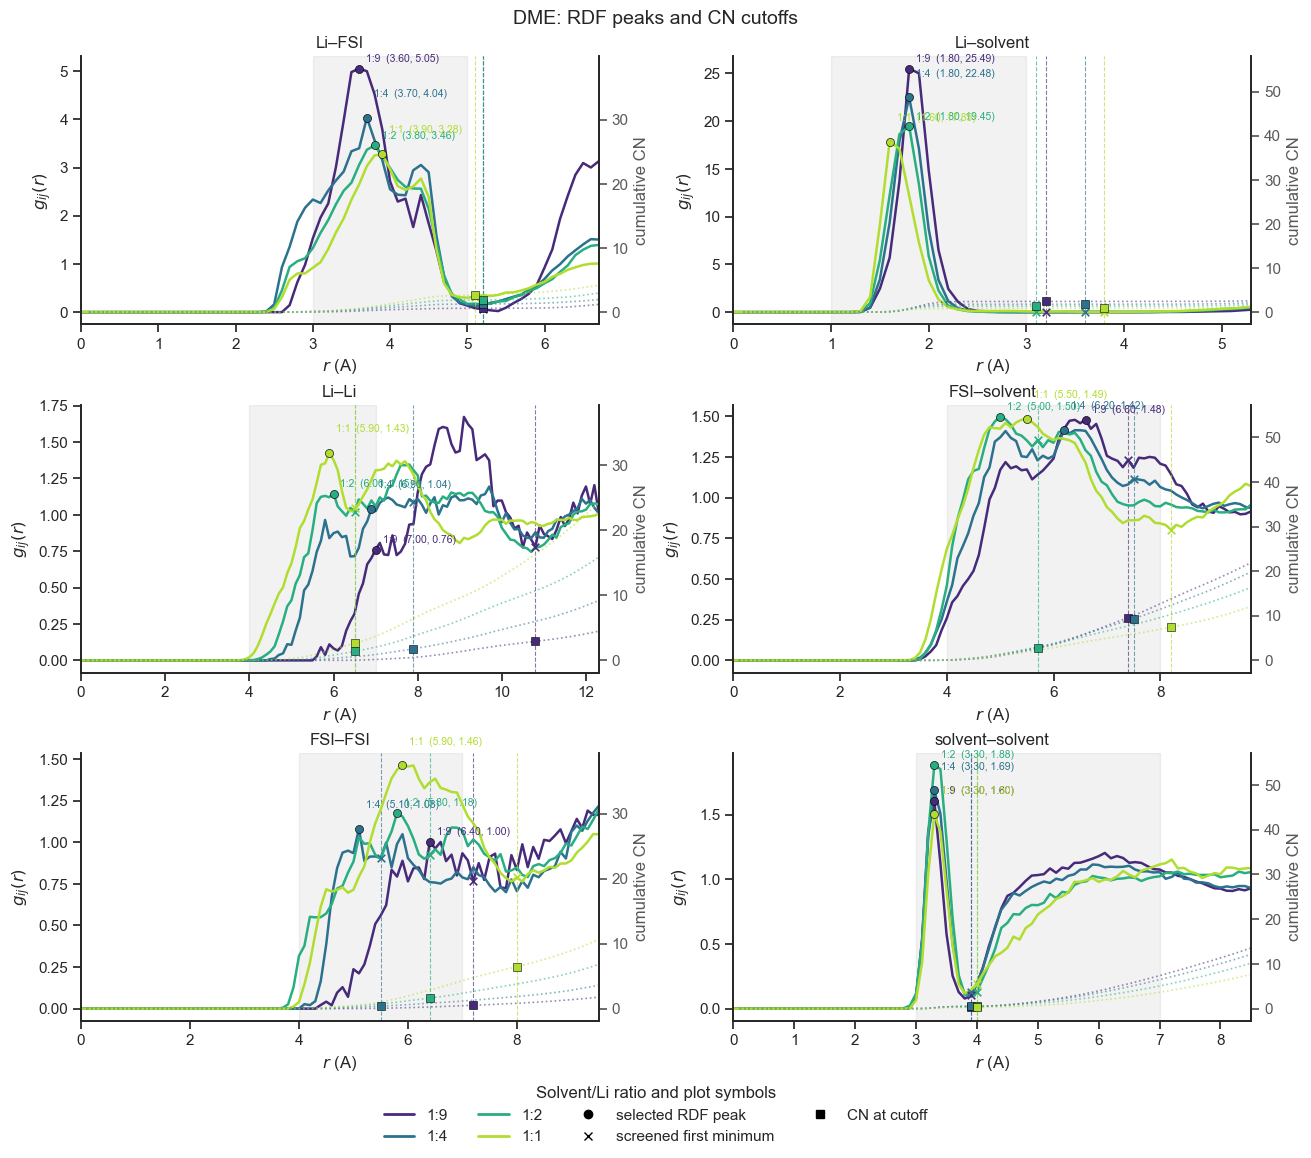

,System,N_Solvent,pair,peak_window_A,peak_r_A,rdf_peak,peak_on_window_edge,first_minimum_r_A,cn_cutoff_selected_A,cn_cutoff_actual_A,cn_cutoff_source,manual_cutoff_override_A,cutoff_minus_minimum_A,cn_center_to_neighbor,a_ij_used
0,DME_1-9.0,9.0,FSI_FSI,"(4.0, 7.0)",6.4,1.004,False,7.2,7.2,7.2,automatic first minimum,None,0.0,0.512,1.000
1,DME_1-4.0,4.0,FSI_FSI,"(4.0, 7.0)",5.1,1.082,False,5.5,5.5,5.5,automatic first minimum,None,0.0,0.372,1.000
2,DME_1-2.0,2.0,FSI_FSI,"(4.0, 7.0)",5.8,1.175,False,6.4,6.4,6.4,automatic first minimum,None,0.0,1.615,1.000
3,DME_1-1.0,1.0,FSI_FSI,"(4.0, 7.0)",5.9,1.464,False,8.0,8.0,8.0,automatic first minimum,None,0.0,6.447,1.000
4,DME_1-9.0,9.0,FSI_solvent,"(4.0, 8.0)",6.6,1.480,False,7.4,7.4,7.4,automatic first minimum,None,0.0,9.584,1.480
5,DME_1-4.0,4.0,FSI_solvent,"(4.0, 8.0)",6.2,1.419,False,7.5,7.5,7.5,automatic first minimum,None,0.0,9.337,1.419
6,DME_1-2.0,2.0,FSI_solvent,"(4.0, 8.0)",5.0,1.497,False,5.7,5.7,5.7,automatic first minimum,None,0.0,2.881,1.497
7,DME_1-1.0,1.0,FSI_solvent,"(4.0, 8.0)",5.5,1.487,False,8.2,8.2,8.2,automatic first minimum,None,0.0,7.422,1.487
8,DME_1-9.0,9.0,Li_FSI,"(3.0, 5.0)",3.6,5.052,False,5.2,5.2,5.2,automatic first minimum,None,0.0,0.602,5.052
9,DME_1-4.0,4.0,Li_FSI,"(3.0, 5.0)",3.7,4.036,False,5.2,5.2,5.2,automatic first minimum,None,0.0,1.270,4.036


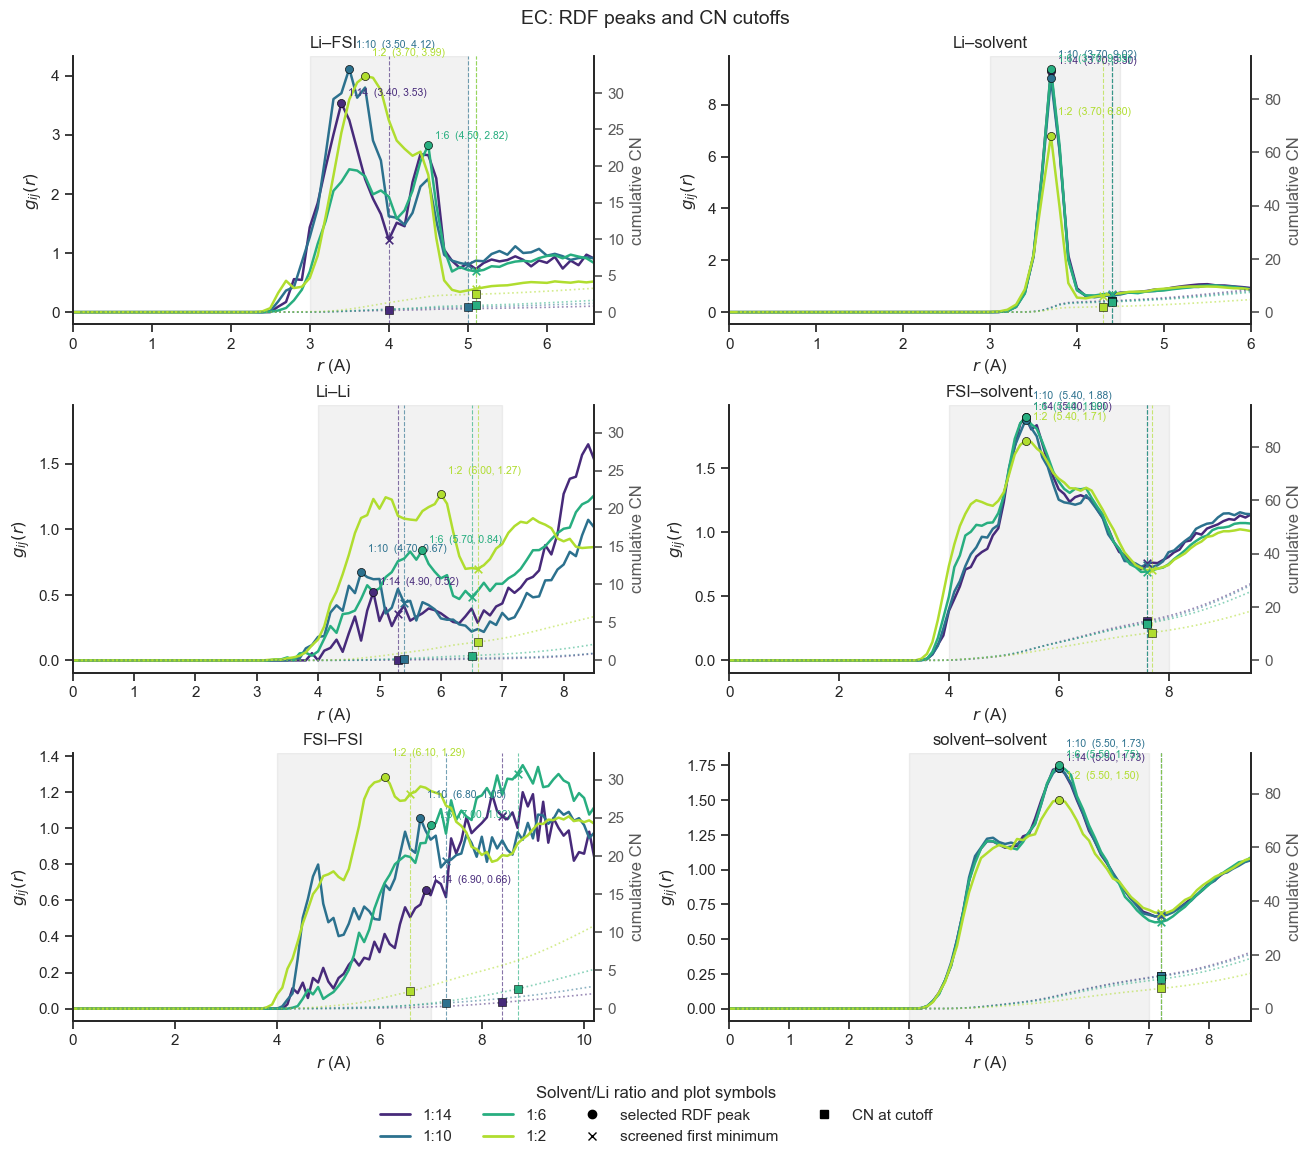

,System,N_Solvent,pair,peak_window_A,peak_r_A,rdf_peak,peak_on_window_edge,first_minimum_r_A,cn_cutoff_selected_A,cn_cutoff_actual_A,cn_cutoff_source,manual_cutoff_override_A,cutoff_minus_minimum_A,cn_center_to_neighbor,a_ij_used
0,EC_1-14.0,14.0,FSI_FSI,"(4.0, 7.0)",6.9,0.657,True,8.4,8.4,8.4,automatic first minimum,None,0.0,0.806,1.000
1,EC_1-10.0,10.0,FSI_FSI,"(4.0, 7.0)",6.8,1.055,False,7.3,7.3,7.3,automatic first minimum,None,0.0,0.731,1.000
2,EC_1-6.0,6.0,FSI_FSI,"(4.0, 7.0)",7.0,1.018,True,8.7,8.7,8.7,automatic first minimum,None,0.0,2.582,1.000
3,EC_1-2.0,2.0,FSI_FSI,"(4.0, 7.0)",6.1,1.287,False,6.6,6.6,6.6,automatic first minimum,None,0.0,2.252,1.000
4,EC_1-14.0,14.0,FSI_solvent,"(4.0, 8.0)",5.4,1.897,False,7.6,7.6,7.6,automatic first minimum,None,0.0,14.766,1.897
5,EC_1-10.0,10.0,FSI_solvent,"(4.0, 8.0)",5.4,1.876,False,7.6,7.6,7.6,automatic first minimum,None,0.0,14.191,1.876
6,EC_1-6.0,6.0,FSI_solvent,"(4.0, 8.0)",5.4,1.896,False,7.6,7.6,7.6,automatic first minimum,None,0.0,13.817,1.896
7,EC_1-2.0,2.0,FSI_solvent,"(4.0, 8.0)",5.4,1.712,False,7.7,7.7,7.7,automatic first minimum,None,0.0,10.421,1.712
8,EC_1-14.0,14.0,Li_FSI,"(3.0, 5.0)",3.4,3.533,False,4.0,4.0,4.0,automatic first minimum,None,0.0,0.228,3.533
9,EC_1-10.0,10.0,Li_FSI,"(3.0, 5.0)",3.5,4.118,False,5.0,5.0,5.0,automatic first minimum,None,0.0,0.684,4.118


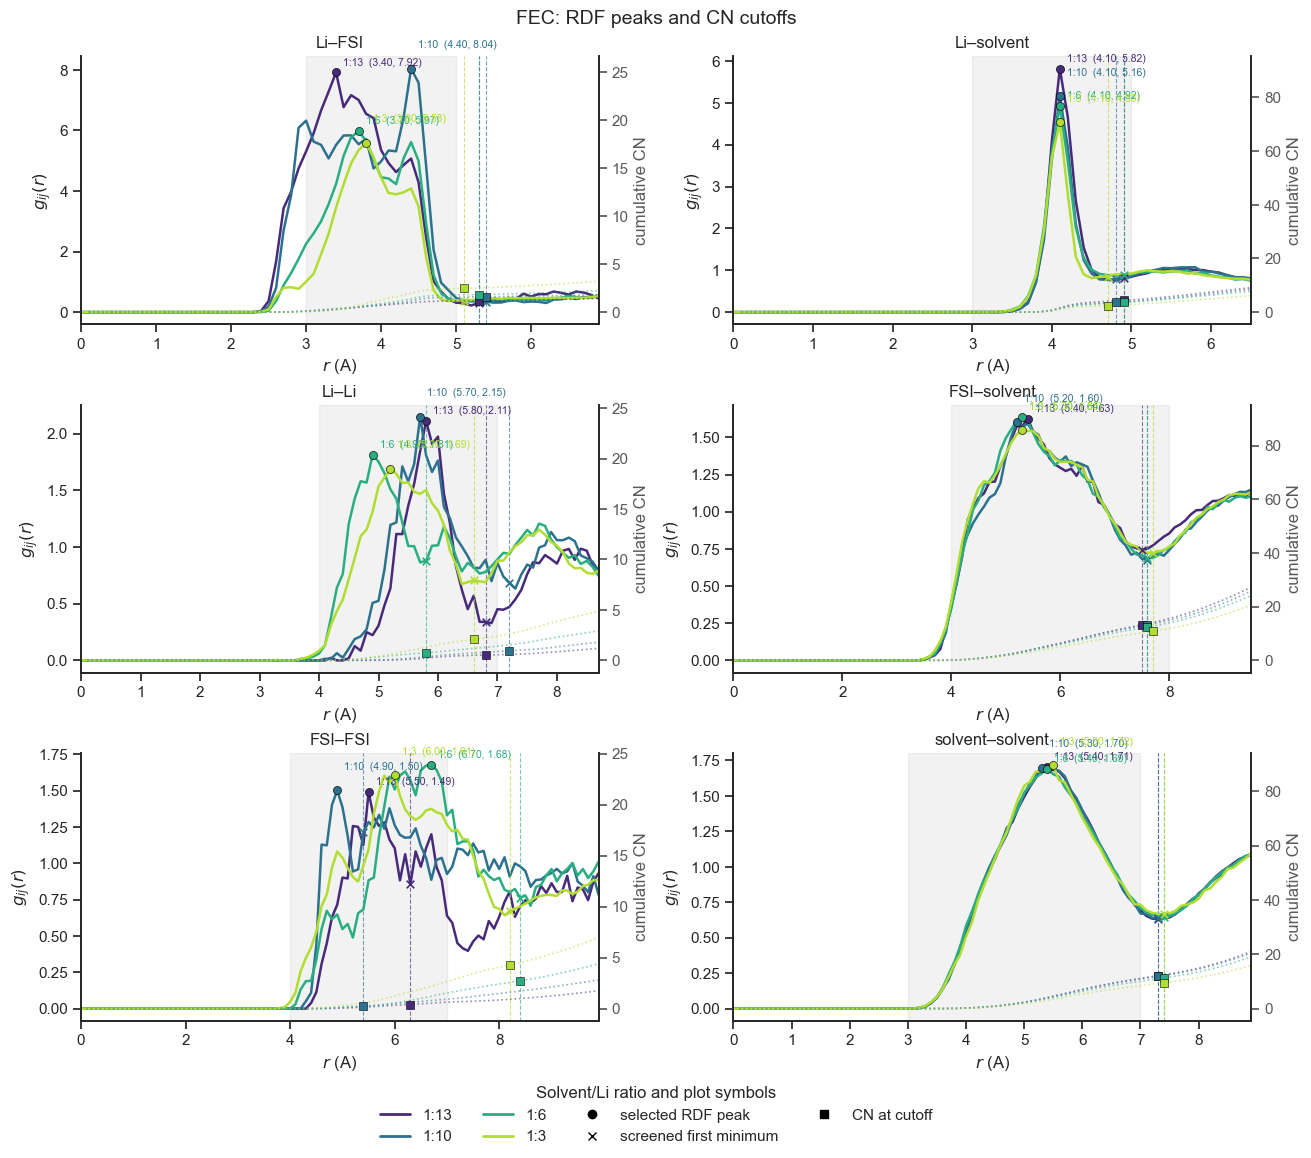

,System,N_Solvent,pair,peak_window_A,peak_r_A,rdf_peak,peak_on_window_edge,first_minimum_r_A,cn_cutoff_selected_A,cn_cutoff_actual_A,cn_cutoff_source,manual_cutoff_override_A,cutoff_minus_minimum_A,cn_center_to_neighbor,a_ij_used
0,FEC_1-13.0,13.0,FSI_FSI,"(4.0, 7.0)",5.5,1.490,False,6.3,6.3,6.3,automatic first minimum,None,0.0,0.403,1.000
1,FEC_1-10.0,10.0,FSI_FSI,"(4.0, 7.0)",4.9,1.502,False,5.4,5.4,5.4,automatic first minimum,None,0.0,0.249,1.000
2,FEC_1-6.0,6.0,FSI_FSI,"(4.0, 7.0)",6.7,1.676,False,8.4,8.4,8.4,automatic first minimum,None,0.0,2.737,1.000
3,FEC_1-3.0,3.0,FSI_FSI,"(4.0, 7.0)",6.0,1.607,False,8.2,8.2,8.2,automatic first minimum,None,0.0,4.277,1.000
4,FEC_1-13.0,13.0,FSI_solvent,"(4.0, 8.0)",5.4,1.627,False,7.5,7.5,7.5,automatic first minimum,None,0.0,13.259,1.627
5,FEC_1-10.0,10.0,FSI_solvent,"(4.0, 8.0)",5.2,1.602,False,7.6,7.6,7.6,automatic first minimum,None,0.0,13.248,1.602
6,FEC_1-6.0,6.0,FSI_solvent,"(4.0, 8.0)",5.3,1.638,False,7.6,7.6,7.6,automatic first minimum,None,0.0,12.434,1.638
7,FEC_1-3.0,3.0,FSI_solvent,"(4.0, 8.0)",5.3,1.548,False,7.7,7.7,7.7,automatic first minimum,None,0.0,10.887,1.548
8,FEC_1-13.0,13.0,Li_FSI,"(3.0, 5.0)",3.4,7.915,False,5.3,5.3,5.3,automatic first minimum,None,0.0,1.171,7.915
9,FEC_1-10.0,10.0,Li_FSI,"(3.0, 5.0)",4.4,8.039,False,5.4,5.4,5.4,automatic first minimum,None,0.0,1.606,8.039


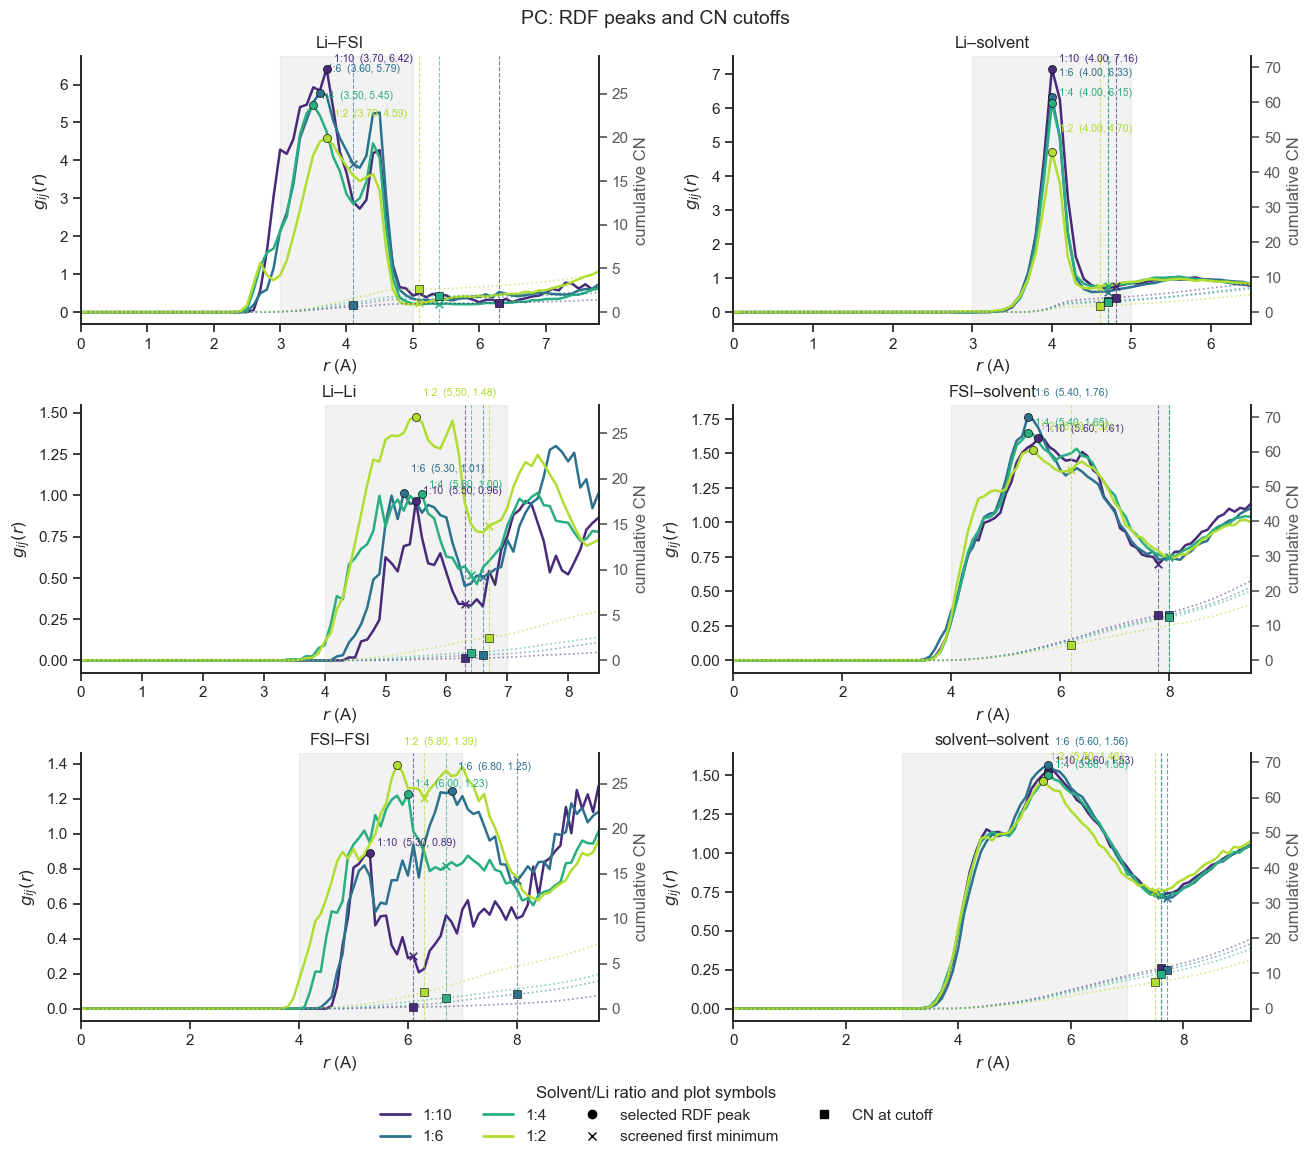

,System,N_Solvent,pair,peak_window_A,peak_r_A,rdf_peak,peak_on_window_edge,first_minimum_r_A,cn_cutoff_selected_A,cn_cutoff_actual_A,cn_cutoff_source,manual_cutoff_override_A,cutoff_minus_minimum_A,cn_center_to_neighbor,a_ij_used
0,PC_1-10.0,10.0,FSI_FSI,"(4.0, 7.0)",5.3,0.890,False,6.1,6.1,6.1,automatic first minimum,None,0.0,0.176,1.000
1,PC_1-6.0,6.0,FSI_FSI,"(4.0, 7.0)",6.8,1.245,False,8.0,8.0,8.0,automatic first minimum,None,0.0,1.607,1.000
2,PC_1-4.0,4.0,FSI_FSI,"(4.0, 7.0)",6.0,1.229,False,6.7,6.7,6.7,automatic first minimum,None,0.0,1.200,1.000
3,PC_1-2.0,2.0,FSI_FSI,"(4.0, 7.0)",5.8,1.392,False,6.3,6.3,6.3,automatic first minimum,None,0.0,1.799,1.000
4,PC_1-10.0,10.0,FSI_solvent,"(4.0, 8.0)",5.6,1.608,False,7.8,7.8,7.8,automatic first minimum,None,0.0,12.957,1.608
5,PC_1-6.0,6.0,FSI_solvent,"(4.0, 8.0)",5.4,1.764,False,8.0,8.0,8.0,automatic first minimum,None,0.0,12.983,1.764
6,PC_1-4.0,4.0,FSI_solvent,"(4.0, 8.0)",5.4,1.648,False,8.0,8.0,8.0,automatic first minimum,None,0.0,12.433,1.648
7,PC_1-2.0,2.0,FSI_solvent,"(4.0, 8.0)",5.5,1.523,False,6.2,6.2,6.2,automatic first minimum,None,0.0,4.389,1.523
8,PC_1-10.0,10.0,Li_FSI,"(3.0, 5.0)",3.7,6.419,False,6.3,6.3,6.3,automatic first minimum,None,0.0,1.082,6.419
9,PC_1-6.0,6.0,Li_FSI,"(3.0, 5.0)",3.6,5.786,False,4.1,4.1,4.1,automatic first minimum,None,0.0,0.863,5.786


In [11]:
rdf_cn_figures = {}
detected_solvents = sorted(
    results["Solvent"].unique(),
    key=solvent_sort_key,
)

review_columns = [
    "System",
    "N_Solvent",
    "pair",
    "peak_window_A",
    "peak_r_A",
    "rdf_peak",
    "peak_on_window_edge",
    "first_minimum_r_A",
    "cn_cutoff_selected_A",
    "cn_cutoff_actual_A",
    "cn_cutoff_source",
    "manual_cutoff_override_A",
    "cutoff_minus_minimum_A",
    "cn_center_to_neighbor",
    "a_ij_used",
]

for solvent in detected_solvents:
    rdf_cn_figures[solvent] = plot_solvent_rdf_cn_diagnostics(
        solvent,
        rdf_data,
        cn_data,
        system_results,
    )
    plt.show()

    solvent_diagnostics = (
        parameter_diagnostics.loc[
            parameter_diagnostics["Solvent"] == solvent,
            review_columns,
        ]
        .sort_values(
            ["pair", "N_Solvent"],
            ascending=[True, False],
        )
        .reset_index(drop=True)
    )

    display(solvent_diagnostics)


## 6. Relative chemical potentials

Full mixing and excess-only chemical potentials are referenced to the most dilute
simulated composition within each solvent. These references are used for the
model-only species plots and the extrapolation checks. The Li⁺ experiment figure
uses the matched experimental/simulation reference defined in Section 8.

In [12]:
SPECIES_COLUMNS = ("Li", "FSI", "Solvent")
SPECIES_PLOT_LABELS = {
    "Li": r"\mathrm{Li^+}",
    "FSI": r"\mathrm{FSI^-}",
    "Solvent": r"\mathrm{solvent}",
}


def add_relative_chemical_potentials(frame: pd.DataFrame) -> pd.DataFrame:
    """Reference full and excess chemical potentials to each solvent's dilute point."""
    output = frame.copy()
    reference_index = output.groupby("Solvent")["N_Solvent"].idxmax()
    potential_columns = [
        f"mu{quantity}_{species}"
        for quantity in ("Mix", "E")
        for species in SPECIES_COLUMNS
    ]
    references = output.loc[
        reference_index,
        ["Solvent", "System", *potential_columns],
    ].rename(
        columns={
            "System": "Reference_System",
            **{column: f"{column}_reference" for column in potential_columns},
        }
    )
    output = output.merge(references, on="Solvent", validate="many_to_one")

    for species in SPECIES_COLUMNS:
        output[f"delta_muMix_{species}_vs_dilute"] = (
            output[f"muMix_{species}"] - output[f"muMix_{species}_reference"]
        )
        output[f"delta_muE_{species}_vs_dilute"] = (
            output[f"muE_{species}"] - output[f"muE_{species}_reference"]
        )

    output["delta_mu_Li_vs_dilute"] = output["delta_muMix_Li_vs_dilute"]
    return output.sort_values(["Solvent", "N_Solvent"], ascending=[True, False])


relative_results = add_relative_chemical_potentials(results)
display(
    relative_results[
        [
            "System",
            "Reference_System",
            "x_Li",
            *[
                f"delta_mu{quantity}_{species}_vs_dilute"
                for species in SPECIES_COLUMNS
                for quantity in ("Mix", "E")
            ],
        ]
    ]
)


,System,Reference_System,x_Li,delta_muMix_Li_vs_dilute,delta_muE_Li_vs_dilute,delta_muMix_FSI_vs_dilute,delta_muE_FSI_vs_dilute,delta_muMix_Solvent_vs_dilute,delta_muE_Solvent_vs_dilute
3,DME_1-9.0,DME_1-9.0,0.090909,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,DME_1-4.0,DME_1-9.0,0.166667,0.087103,0.071530,0.027921,0.012348,-0.024616,-0.019354
1,DME_1-2.0,DME_1-9.0,0.250000,0.202131,0.176140,0.062994,0.037004,-0.040850,-0.028197
0,DME_1-1.0,DME_1-9.0,0.333333,0.149062,0.115680,0.027929,-0.005453,-0.176896,-0.153825
7,EC_1-14.0,EC_1-14.0,0.062500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,EC_1-10.0,EC_1-14.0,0.083333,0.069801,0.062410,0.014592,0.007201,-0.006461,-0.005208
5,EC_1-6.0,EC_1-14.0,0.125000,0.166816,0.149008,0.038956,0.021147,-0.027431,-0.023470
4,EC_1-2.0,EC_1-14.0,0.250000,0.377345,0.341727,0.060019,0.024402,-0.078308,-0.063930
11,FEC_1-13.0,FEC_1-13.0,0.066667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,FEC_1-10.0,FEC_1-13.0,0.083333,0.063399,0.057666,-0.003315,-0.009048,-0.000755,0.000253


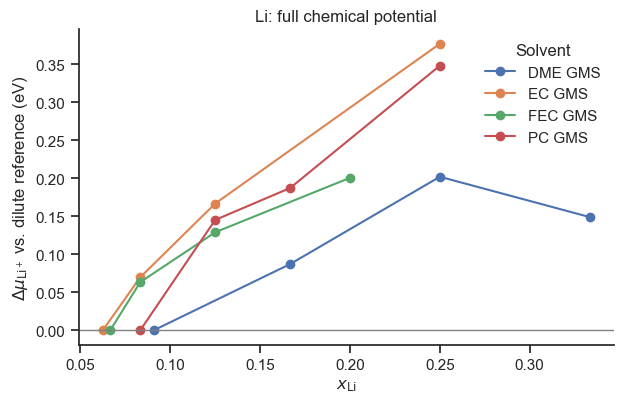

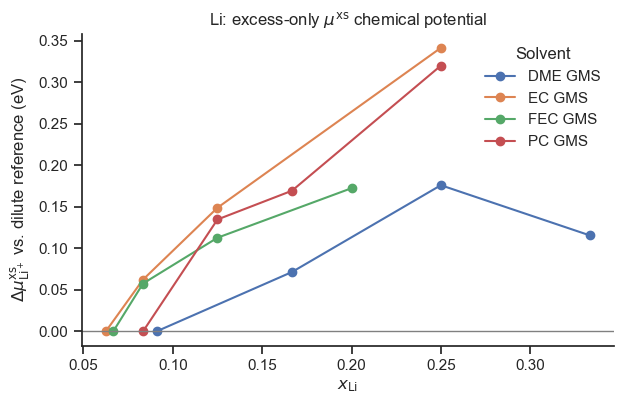

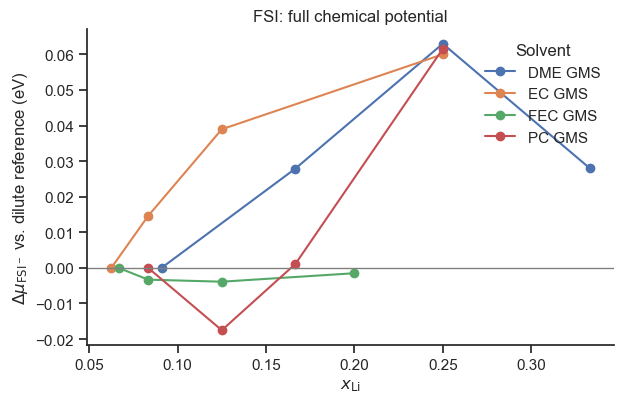

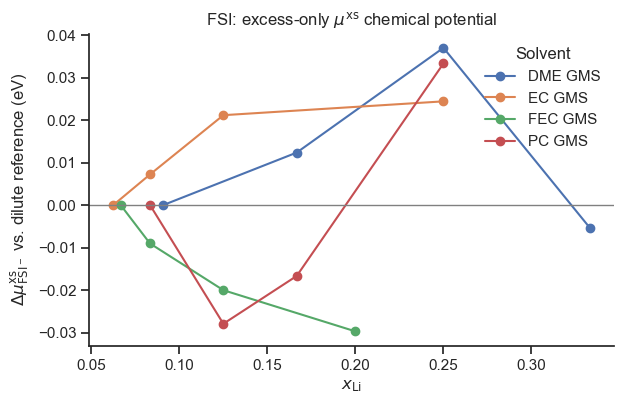

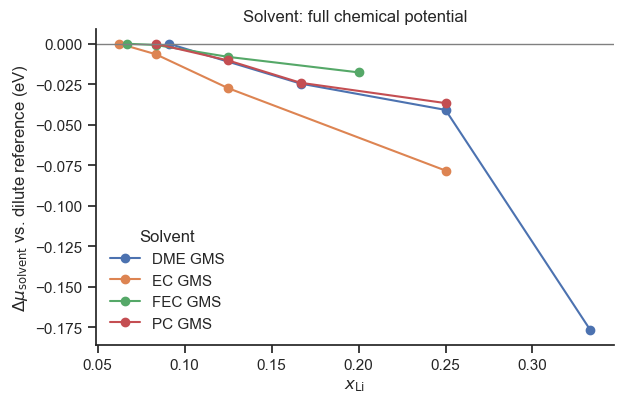

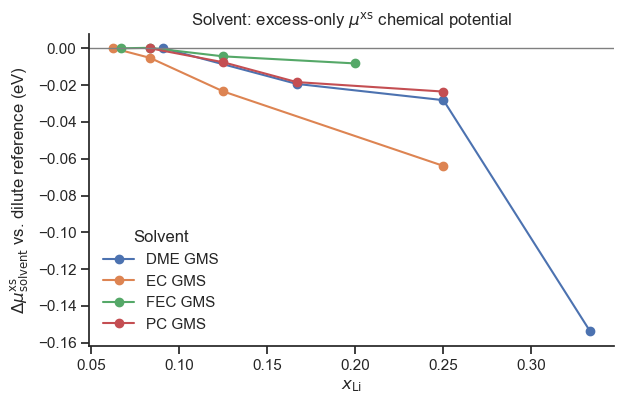

In [13]:
def chemical_potential_ylabel(species: str, quantity: str) -> str:
    label = SPECIES_PLOT_LABELS[species]
    if quantity == "Mix":
        return rf"$\Delta\mu_{{{label}}}$ vs. dilute reference ({ENERGY_UNIT})"
    if quantity == "E":
        return (
            rf"$\Delta\mu_{{{label}}}^{{\mathrm{{xs}}}}$ "
            rf"vs. dilute reference ({ENERGY_UNIT})"
        )
    raise ValueError("quantity must be 'Mix' or 'E'")


def plot_pointwise_chemical_potential(
    frame: pd.DataFrame,
    species: str,
    quantity: str,
) -> tuple[plt.Figure, plt.Axes]:
    """Plot one species' pointwise full or GMS excess chemical potential."""
    value_column = f"delta_mu{quantity}_{species}_vs_dilute"
    fig, ax = plt.subplots(figsize=(6.4, 4.2))

    for solvent in sorted(frame["Solvent"].unique(), key=solvent_sort_key):
        subset = frame.loc[frame["Solvent"] == solvent].sort_values("x_Li")
        ax.plot(subset["x_Li"], subset[value_column], marker="o", label=f"{solvent} GMS")

    ax.axhline(0.0, color="0.5", linewidth=1.0)
    ax.set_xlabel(r"$x_{\mathrm{Li}}$")
    ax.set_ylabel(chemical_potential_ylabel(species, quantity))
    potential_name = "full" if quantity == "Mix" else r"excess-only $\mu^{\mathrm{xs}}$"
    ax.set_title(f"{species}: {potential_name} chemical potential")
    ax.legend(title="Solvent", frameon=False)
    sns.despine()
    fig.tight_layout()
    return fig, ax


pointwise_figures = {}
for species in SPECIES_COLUMNS:
    for quantity in ("Mix", "E"):
        pointwise_figures[(species, quantity)] = plot_pointwise_chemical_potential(
            relative_results, species, quantity
        )
        plt.show()


## 7. Frozen-parameter extrapolation checks

For each source composition, hold its affinities and coordination numbers fixed
and vary only the composition over that solvent's sampled range. Curves are
colored by their source Li mole fraction, and open circles mark the independently
parameterized pointwise results. This tests parameter transferability, not a
global fit. Each curve uses the solvent's pointwise dilute reference; a transferred
curve need not pass through zero at the dilute endpoint.

In [14]:
def extrapolate_local_parameter_sets(
    system_results: Mapping[str, dict[str, object]],
    relative_results: pd.DataFrame,
    model: GMSModel,
    *,
    grid_points: int = 300,
) -> pd.DataFrame:
    """Evaluate every local parameter set over its solvent's sampled composition range."""
    records: list[dict[str, object]] = []

    for solvent, subset in relative_results.groupby("Solvent", sort=True):
        subset = subset.sort_values("x_Li")
        n_grid = np.linspace(
            subset["N_Solvent"].min(),
            subset["N_Solvent"].max(),
            grid_points,
        )
        compositions = np.column_stack(
            [np.ones_like(n_grid), np.ones_like(n_grid), n_grid]
        )
        compositions /= compositions.sum(axis=1, keepdims=True)

        for source in subset.itertuples(index=False):
            parameters = system_results[source.System]
            mu_excess = np.vstack(
                [
                    model.excess_chemical_potential(
                        composition, parameters["Z"], parameters["affinity"]
                    )
                    for composition in compositions
                ]
            )
            mu_mixing = model.thermal_energy * np.log(compositions) + mu_excess

            for grid_index, (n_solvent, composition) in enumerate(
                zip(n_grid, compositions)
            ):
                record = {
                    "Solvent": solvent,
                    "Source_System": source.System,
                    "Source_N_Solvent": source.N_Solvent,
                    "Source_x_Li": source.x_Li,
                    "N_Solvent": n_solvent,
                    "x_Li": composition[0],
                }
                for species_index, species in enumerate(SPECIES_COLUMNS):
                    record[f"delta_muMix_{species}_vs_dilute"] = (
                        mu_mixing[grid_index, species_index]
                        - getattr(source, f"muMix_{species}_reference")
                    )
                    record[f"delta_muE_{species}_vs_dilute"] = (
                        mu_excess[grid_index, species_index]
                        - getattr(source, f"muE_{species}_reference")
                    )
                records.append(record)

    return pd.DataFrame.from_records(records)


extrapolation_results = extrapolate_local_parameter_sets(
    system_results, relative_results, model
)
display(extrapolation_results.head())


,Solvent,Source_System,Source_N_Solvent,Source_x_Li,N_Solvent,x_Li,delta_muMix_Li_vs_dilute,delta_muE_Li_vs_dilute,delta_muMix_FSI_vs_dilute,delta_muE_FSI_vs_dilute,delta_muMix_Solvent_vs_dilute,delta_muE_Solvent_vs_dilute
0,DME,DME_1-9.0,9.0,0.090909,1.000000,0.333333,0.176699,0.143317,0.009786,-0.023596,-0.066921,-0.043851
1,DME,DME_1-9.0,9.0,0.090909,1.026756,0.330387,0.175038,0.141884,0.009888,-0.023266,-0.065382,-0.042762
2,DME,DME_1-9.0,9.0,0.090909,1.053512,0.327492,0.173410,0.140483,0.009981,-0.022947,-0.063907,-0.041721
3,DME,DME_1-9.0,9.0,0.090909,1.080268,0.324647,0.171815,0.139111,0.010067,-0.022637,-0.062491,-0.040726
4,DME,DME_1-9.0,9.0,0.090909,1.107023,0.321851,0.170250,0.137768,0.010146,-0.022336,-0.061133,-0.039774


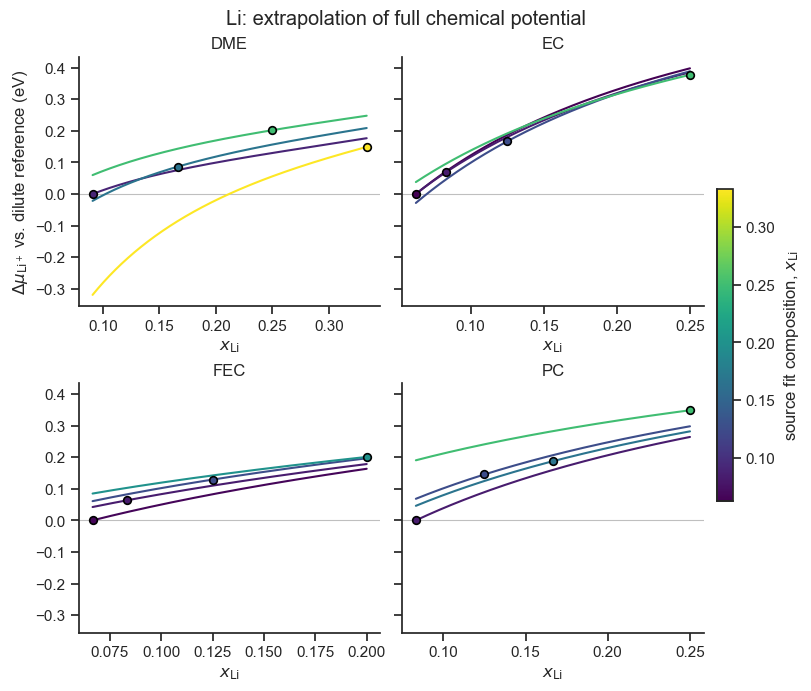

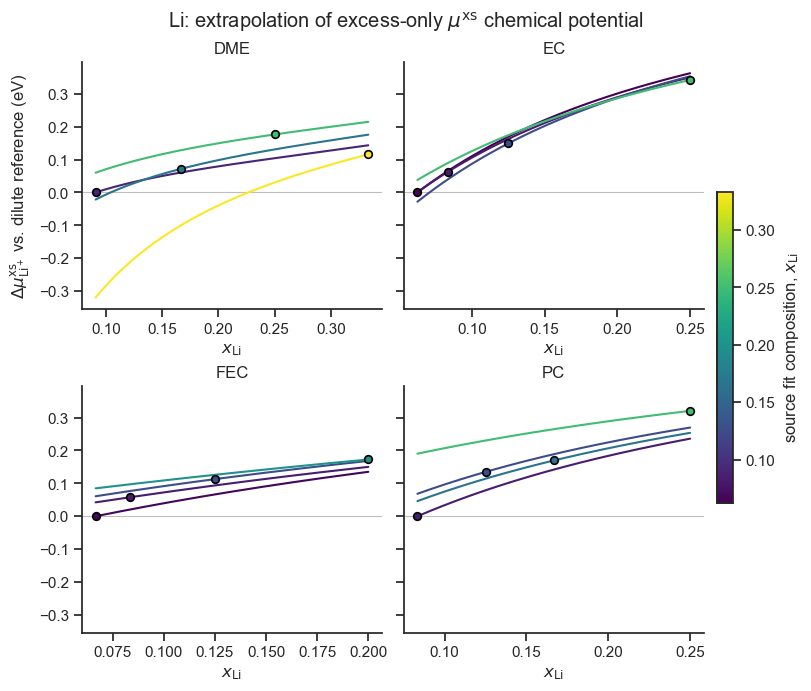

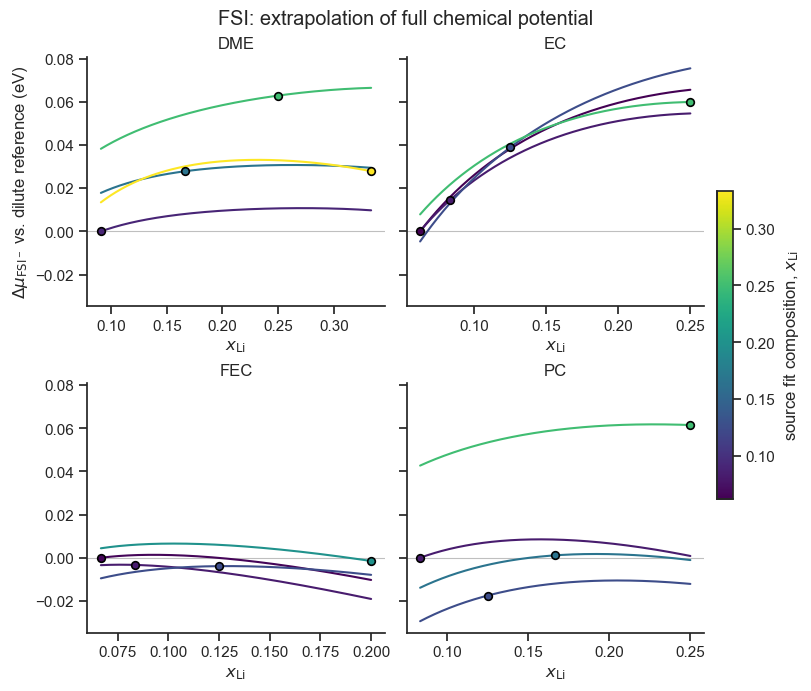

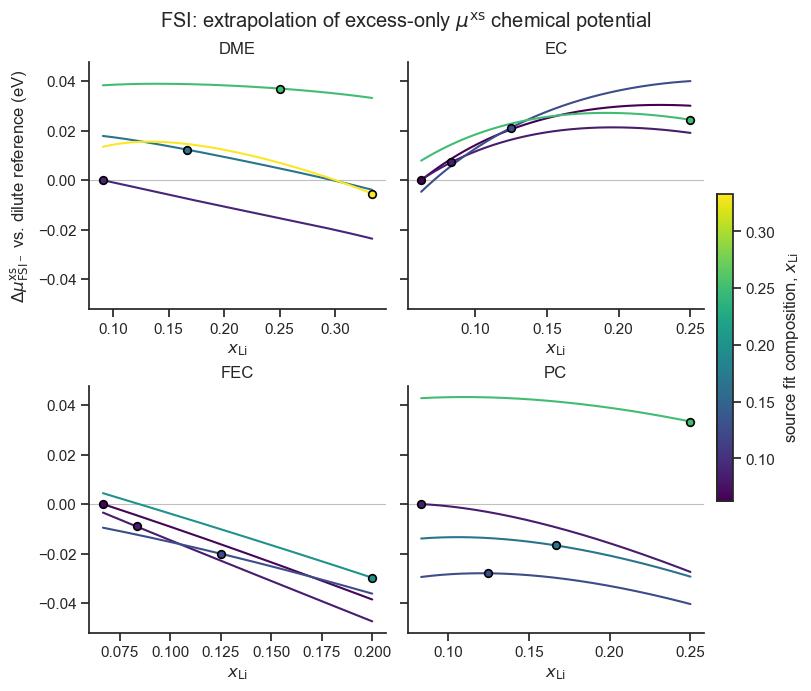

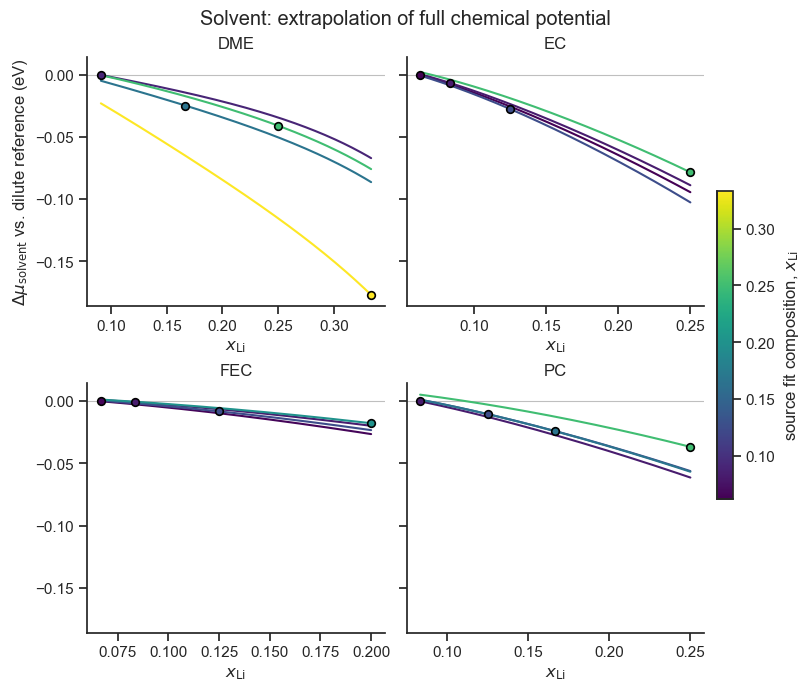

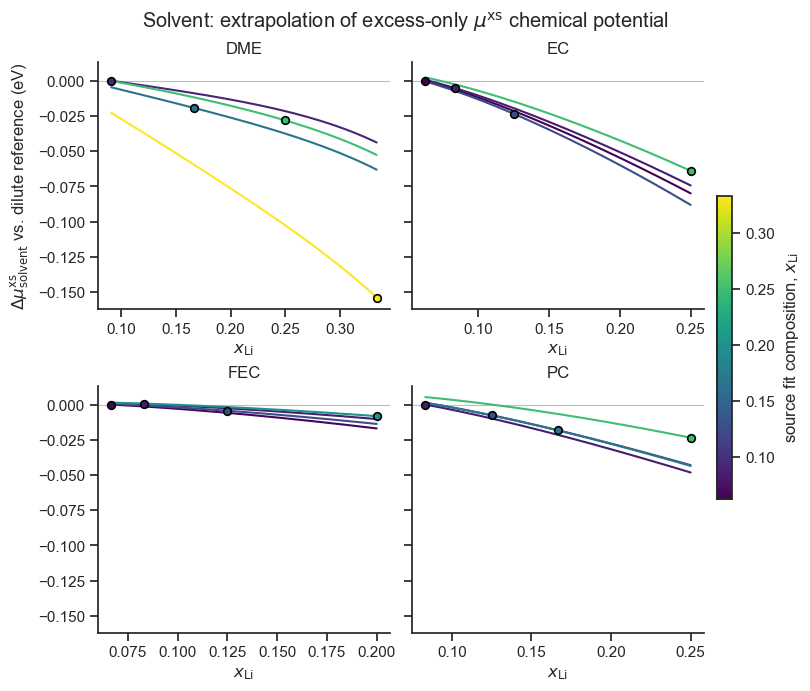

In [15]:
def plot_parameter_extrapolation(
    extrapolation_frame: pd.DataFrame,
    benchmark_frame: pd.DataFrame,
    species: str,
    quantity: str,
) -> tuple[plt.Figure, np.ndarray]:
    """Plot a compact solvent-panel grid for one species and one contribution."""
    value_column = f"delta_mu{quantity}_{species}_vs_dilute"
    solvents = sorted(extrapolation_frame["Solvent"].unique(), key=solvent_sort_key)
    ncols = min(2, len(solvents))
    nrows = ceil(len(solvents) / ncols)

    source_x_min = float(extrapolation_frame["Source_x_Li"].min())
    source_x_max = float(extrapolation_frame["Source_x_Li"].max())
    color_norm = plt.Normalize(source_x_min, source_x_max)
    color_map = plt.colormaps["viridis"]

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.0 * ncols, 3.4 * nrows),
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, solvent in zip(axes.flat, solvents):
        curves = extrapolation_frame.query("Solvent == @solvent")
        benchmarks = benchmark_frame.query("Solvent == @solvent").sort_values("x_Li")

        for source_system, curve in curves.groupby("Source_System", sort=False):
            curve = curve.sort_values("x_Li")
            source_x = float(curve["Source_x_Li"].iloc[0])
            color = color_map(color_norm(source_x))
            ax.plot(curve["x_Li"], curve[value_column], color=color, linewidth=1.5)
            source_row = benchmarks.loc[benchmarks["System"] == source_system].iloc[0]
            ax.scatter(
                source_row["x_Li"], source_row[value_column], color=color, s=20, zorder=4
            )

        ax.plot(
            benchmarks["x_Li"],
            benchmarks[value_column],
            linestyle="none",
            marker="o",
            markersize=5.5,
            markerfacecolor="none",
            markeredgecolor="black",
            markeredgewidth=1.2,
            zorder=5,
        )
        ax.axhline(0.0, color="0.75", linewidth=0.8, zorder=0)
        ax.set_title(solvent)
        ax.set_xlabel(r"$x_{\mathrm{Li}}$")

    for ax in axes.flat[len(solvents):]:
        ax.remove()

    axes[0, 0].set_ylabel(chemical_potential_ylabel(species, quantity))
    scalar_mappable = plt.cm.ScalarMappable(norm=color_norm, cmap=color_map)
    scalar_mappable.set_array([])
    colorbar = fig.colorbar(
        scalar_mappable,
        ax=[ax for ax in axes.flat[:len(solvents)]],
        fraction=0.025,
        pad=0.02,
    )
    colorbar.set_label(r"source fit composition, $x_{\mathrm{Li}}$")
    potential_name = "full" if quantity == "Mix" else r"excess-only $\mu^{\mathrm{xs}}$"
    fig.suptitle(f"{species}: extrapolation of {potential_name} chemical potential")
    sns.despine(fig=fig)
    return fig, axes


extrapolation_figures = {}
for species in SPECIES_COLUMNS:
    for quantity in ("Mix", "E"):
        extrapolation_figures[(species, quantity)] = plot_parameter_extrapolation(
            extrapolation_results, relative_results, species, quantity
        )
        plt.show()


## 8. Li$^+$ benchmark against experimental CV-average shifts

For each solvent, select the most dilute simulation/experiment ratio pair within
`REFERENCE_RATIO_TOLERANCE`; each series is referenced to its own member of that
pair. Match remaining points by solvent/Li ratio using `POINT_MATCH_TOLERANCE`.
For monovalent Li$^+$, potential differences in V equal the corresponding
chemical-potential differences in eV per ion under the benchmark convention:
$\Delta\mu_{\mathrm{Li^+}}^{\mathrm{exp}}=\Delta U_{\mathrm{CV}}$.
GMS values include ideal mixing. Absolute potential offsets cancel in these
within-solvent differences.

The paper figure retains its specified display filters: EC experimental points
must lie within the simulation range; DME model points must not exceed the maximum
experimental Li mole fraction (the dilute end is retained). These are display
filters applied after referencing, not changes to the fitted parameters or the
underlying result tables. Error metrics below use only matched points visible
under these filters and exclude the forced-zero reference pair.

In [16]:
def read_experimental_cv_data(path: str | Path) -> pd.DataFrame:
    """Read solvent, solvent/Li ratio, and the last-column CV-average potential."""
    raw = pd.read_csv(path, sep=r"\s+", comment="#", header=None)
    if raw.shape[1] < 4:
        raise ValueError(
            f"Expected at least four whitespace-separated columns in {path}; "
            f"found {raw.shape[1]}"
        )
    frame = raw.iloc[:, [0, 1, raw.shape[1] - 1]].copy()
    frame.columns = ["Solvent", "N_Solvent", "U_CV_average_V"]
    frame["Solvent"] = frame["Solvent"].astype(str)
    frame["N_Solvent"] = pd.to_numeric(frame["N_Solvent"], errors="raise")
    frame["U_CV_average_V"] = pd.to_numeric(frame["U_CV_average_V"], errors="raise")
    frame = frame.loc[frame["Solvent"].isin(SELECTED_SOLVENTS)].copy()
    if (frame["N_Solvent"] <= 0).any() or not np.isfinite(frame[["N_Solvent", "U_CV_average_V"]].to_numpy()).all():
        raise ValueError("Experimental ratios must be positive and all values finite")
    frame["x_Li"] = 1.0 / (frame["N_Solvent"] + 2.0)
    if frame.duplicated(["Solvent", "N_Solvent"]).any():
        raise ValueError("Duplicate solvent/ratio rows in the experimental table")
    return frame.sort_values(["Solvent", "N_Solvent"], ascending=[True, False])


experimental_data = read_experimental_cv_data(EXPERIMENT_FILE)
display(experimental_data)


,Solvent,N_Solvent,U_CV_average_V,x_Li
2,DME,8.9,-3.40,0.091743
3,DME,4.0,-3.34,0.166667
4,DME,2.0,-3.18,0.250000
12,EC,13.8,-3.24,0.063291
13,EC,10.0,-3.21,0.083333
14,EC,6.0,-3.16,0.125000
15,EC,4.0,-3.09,0.166667
16,EC,2.0,-2.94,0.250000
17,EC,1.5,-2.88,0.285714
18,FEC,12.9,-3.05,0.067114


In [17]:
def build_gms_experiment_comparison(
    gms_frame: pd.DataFrame,
    experiment_frame: pd.DataFrame,
    *,
    reference_tolerance: float = REFERENCE_RATIO_TOLERANCE,
    match_tolerance: float = POINT_MATCH_TOLERANCE,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Reference both series within solvent and make a nearest-ratio match table."""
    gms_series = []
    experiment_series = []
    reference_rows = []
    match_rows = []

    common_solvents = sorted(
        set(gms_frame["Solvent"]) & set(experiment_frame["Solvent"]),
        key=solvent_sort_key,
    )
    for solvent in common_solvents:
        gms = gms_frame.loc[gms_frame["Solvent"] == solvent].copy()
        exp = experiment_frame.loc[experiment_frame["Solvent"] == solvent].copy()

        candidates = []
        for gms_index, gms_row in gms.iterrows():
            for exp_index, exp_row in exp.iterrows():
                difference = abs(gms_row["N_Solvent"] - exp_row["N_Solvent"])
                if difference <= reference_tolerance:
                    candidates.append(
                        (
                            min(gms_row["N_Solvent"], exp_row["N_Solvent"]),
                            -difference,
                            gms_index,
                            exp_index,
                        )
                    )
        if not candidates:
            warnings.warn(
                f"No reference ratio match for {solvent} within {reference_tolerance:g}",
                stacklevel=2,
            )
            continue

        # Largest shared ratio = most dilute matched pair; nearest pair breaks ties.
        _, _, gms_reference_index, exp_reference_index = max(candidates)
        gms_reference = gms.loc[gms_reference_index]
        exp_reference = exp.loc[exp_reference_index]

        gms["delta_mu_GMS_eV"] = (gms["muMix_Li"] - gms_reference["muMix_Li"]) * (1.0 if ENERGY_UNIT == "eV" else 1.0 / 96.48533212)
        exp["delta_mu_experiment_eV"] = (
            exp["U_CV_average_V"] - exp_reference["U_CV_average_V"]
        )
        gms["Reference_N_GMS"] = gms_reference["N_Solvent"]
        exp["Reference_N_experiment"] = exp_reference["N_Solvent"]
        gms_series.append(gms)
        experiment_series.append(exp)

        reference_rows.append(
            {
                "Solvent": solvent,
                "Reference_N_GMS": gms_reference["N_Solvent"],
                "Reference_N_experiment": exp_reference["N_Solvent"],
                "ratio_difference": abs(
                    gms_reference["N_Solvent"] - exp_reference["N_Solvent"]
                ),
            }
        )

        # Match only measured/computed ratios that are close enough; unmatched
        # points remain visible in the overlay plot but are excluded from metrics.
        for exp_index, exp_row in exp.iterrows():
            differences = (gms["N_Solvent"] - exp_row["N_Solvent"]).abs()
            nearest_index = differences.idxmin()
            if differences.loc[nearest_index] > match_tolerance:
                continue
            gms_row = gms.loc[nearest_index]
            match_rows.append(
                {
                    "Solvent": solvent,
                    "N_GMS": gms_row["N_Solvent"],
                    "N_experiment": exp_row["N_Solvent"],
                    "delta_mu_GMS_eV": gms_row["delta_mu_GMS_eV"],
                    "delta_mu_experiment_eV": exp_row["delta_mu_experiment_eV"],
                    "residual_GMS_minus_experiment_eV": (
                        gms_row["delta_mu_GMS_eV"]
                        - exp_row["delta_mu_experiment_eV"]
                    ),
                }
            )

    if not gms_series:
        raise ValueError("No solvents have a usable GMS/experimental reference pair")

    gms_output = pd.concat(gms_series, ignore_index=True)
    exp_output = pd.concat(experiment_series, ignore_index=True)
    references = pd.DataFrame(reference_rows)
    matches = pd.DataFrame(match_rows)
    return gms_output, exp_output, references, matches


(
    gms_comparison,
    experimental_comparison,
    comparison_references,
    comparison_matches,
) = build_gms_experiment_comparison(results, experimental_data)

display(comparison_references)
display(comparison_matches)


# Report errors for visible, non-reference matches only.
if not comparison_matches.empty:
    matched = comparison_matches.merge(comparison_references, on="Solvent", validate="many_to_one")
    matched["is_reference_pair"] = (
        np.isclose(matched["N_GMS"], matched["Reference_N_GMS"]) &
        np.isclose(matched["N_experiment"], matched["Reference_N_experiment"]))
    matched["included_in_figure"] = True
    for solvent, group in matched.groupby("Solvent"):
        sim = gms_comparison.loc[gms_comparison["Solvent"] == solvent]
        exp = experimental_comparison.loc[experimental_comparison["Solvent"] == solvent]
        if solvent == "EC":
            x_exp = 1.0/(group["N_experiment"]+2.0)
            matched.loc[group.index, "included_in_figure"] = x_exp.between(sim["x_Li"].min()-1e-10, sim["x_Li"].max()+1e-10)
        elif solvent == "DME":
            x_sim = 1.0/(group["N_GMS"]+2.0)
            matched.loc[group.index, "included_in_figure"] = x_sim <= exp["x_Li"].max()+1e-10
    comparison_matches = matched
    metrics_input = matched.loc[matched["included_in_figure"] & ~matched["is_reference_pair"]]
    comparison_metrics = metrics_input.groupby("Solvent")["residual_GMS_minus_experiment_eV"].agg(
        n="size", MAE_eV=lambda v: v.abs().mean(), RMSE_eV=lambda v: np.sqrt(np.mean(v**2))
    ).reset_index()
else:
    comparison_metrics = pd.DataFrame(columns=["Solvent", "n", "MAE_eV", "RMSE_eV"])
display(comparison_metrics)


,Solvent,Reference_N_GMS,Reference_N_experiment,ratio_difference
0,DME,9.0,8.9,0.1
1,EC,14.0,13.8,0.2
2,FEC,13.0,12.9,0.1
3,PC,10.0,10.6,0.6


,Solvent,N_GMS,N_experiment,delta_mu_GMS_eV,delta_mu_experiment_eV,residual_GMS_minus_experiment_eV
0,DME,9.0,8.9,0.000000,0.00,0.000000
1,DME,4.0,4.0,0.087103,0.06,0.027103
2,DME,2.0,2.0,0.202131,0.22,-0.017869
3,EC,14.0,13.8,0.000000,0.00,0.000000
4,EC,10.0,10.0,0.069801,0.03,0.039801
5,EC,6.0,6.0,0.166816,0.08,0.086816
6,EC,2.0,2.0,0.377345,0.30,0.077345
7,EC,2.0,1.5,0.377345,0.36,0.017345
8,FEC,13.0,12.9,0.000000,0.00,0.000000
9,FEC,10.0,10.0,0.063399,0.02,0.043399


,Solvent,n,MAE_eV,RMSE_eV
0,DME,2,0.022486,0.022955
1,EC,3,0.067987,0.070954
2,FEC,3,0.044387,0.052410
3,PC,3,0.077015,0.077371


### Publication figure

Fixed panel order, dimensions, typography, line styles, markers, axis limits,
legend placement, and display filters reproduce the specified paper figure.

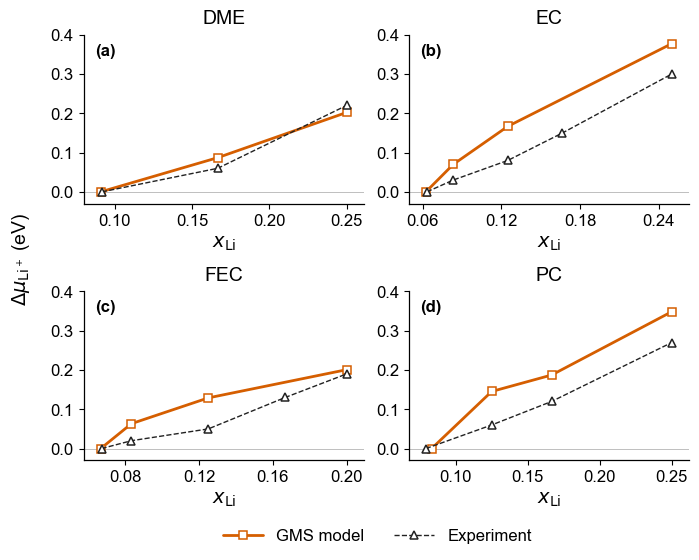

In [21]:
PUBLICATION_STYLE = {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "mathtext.fontset": "dejavusans",
        "font.size": 12,
        "axes.labelsize": 14,
        "axes.titlesize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 12,
        "axes.linewidth": 0.9,
        "axes.edgecolor": "black",
        "axes.grid": False,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "text.color": "black",
        "axes.labelcolor": "black",
        "xtick.color": "black",
        "ytick.color": "black",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.bbox": None,
    }

from matplotlib.ticker import MaxNLocator


def plot_gms_over_experiment(
    gms_frame: pd.DataFrame,
    experiment_frame: pd.DataFrame,
) -> tuple[plt.Figure, np.ndarray]:
    """Publication comparison for DME, EC, FEC, and PC."""
    solvents = ("DME", "EC", "FEC", "PC")

    for name, frame in (
        ("GMS", gms_frame),
        ("experiment", experiment_frame),
    ):
        if frame is not None:
            missing = set(solvents) - set(frame["Solvent"])
            if missing:
                raise ValueError(f"{name}: missing solvents {sorted(missing)}")

    # Local settings: other notebook figures retain their original styling.
    style = PUBLICATION_STYLE

    with plt.rc_context(style):
        # Final double-column size; font sizes are specified at this size.
        fig, axes = plt.subplots(
            2, 2, figsize=(7.0, 5.6), sharey=False
        )
        fig.subplots_adjust(
            left=0.12, right=0.985,
            bottom=0.19, top=0.95,
            wspace=0.16, hspace=0.52,
        )

        for letter, ax, solvent in zip("abcd", axes.flat, solvents):
            gms = gms_frame.loc[
                gms_frame["Solvent"] == solvent
            ].sort_values("x_Li")

            exp = experiment_frame.loc[
                experiment_frame["Solvent"] == solvent
            ].sort_values("x_Li")

            # Remove EC experimental points outside the simulation interval.
            # Filtering by x_Li is robust to the input table's row order.
            # Preserve the chemical-potential reference already applied.
            if solvent == "EC":
                xmin, xmax = gms["x_Li"].min(), gms["x_Li"].max()
                tol = 1e-10
                exp = exp.loc[
                    exp["x_Li"].between(xmin - tol, xmax + tol)
                ]

            # Remove DME GMS points outside the experimental interval.
            if solvent == "DME":
                xmin, xmax = exp["x_Li"].min(), exp["x_Li"].max()
                tol = 1e-10
                gms = gms.loc[
                    gms["x_Li"].between(0, xmax + tol)
                ]

            ax.axhline(
                0.0, color="0.75", linewidth=0.7, zorder=0
            )

            # GMS: vermilion solid line with open square markers.
            ax.plot(
                gms["x_Li"],
                gms["delta_mu_GMS_eV"],
                color="#D55E00",
                linestyle="-",
                marker="s",
                linewidth=2.0,
                markersize=5.2,
                markerfacecolor="white",
                markeredgewidth=1.1,
                label="GMS model",
                zorder=3,
            )

            # Experiment: dark dashed line with open triangle markers.
            ax.plot(
                exp["x_Li"],
                exp["delta_mu_experiment_eV"],
                color="#222222",
                linestyle="--",
                marker="^",
                markersize=5.2,
                markerfacecolor="white",
                markeredgewidth=1.1,
                linewidth=1.0,
                label="Experiment",
                zorder=4,
            )

            ax.set_title(solvent, pad=8)
            ax.text(
                0.04, 0.95, f"({letter})",
                transform=ax.transAxes,
                ha="left", va="top",
                fontsize=12, fontweight="bold",
            )
            ax.set_xlabel(r"$x_{\mathrm{Li}}$", labelpad=4)

            ax.set_ylim(-0.03, 0.4)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.tick_params(
                axis="both",
                direction="out",
                length=3.5,
                width=0.8,
                top=False,
                right=False,
            )

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.spines["left"].set_visible(True)
            ax.spines["bottom"].set_visible(True)
            ax.margins(x=0.07, y=0.12)

        # Shared y-axis and legend avoid repeated text inside the panels.
        fig.supylabel(
            r"$\Delta\mu_{\mathrm{Li^+}}$ (eV)",
            x=0.015, y=0.55,
            fontsize=14,
        )
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(
            handles, labels,
            loc="lower center",
            bbox_to_anchor=(0.54, 0.015),
            ncol=len(handles),
            frameon=False,
            handlelength=2.4,
            columnspacing=1.8,
        )

    return fig, axes


gms_experiment_figure = plot_gms_over_experiment(
    gms_comparison,
    experimental_comparison,
)

# save png figure
gms_experiment_figure[0].savefig("../data/figures/Li_potential_gms_experiment_comparison.png", dpi=500, bbox_inches="tight")

## 9. FSI$^-$ and solvent chemical potentials

The same publication layout and GMS curve style are used for the other species,
with no experimental series. Full and excess-only versions are shown. Each
solvent uses its most dilute simulated reference. All simulated compositions are
included: the EC/DME display filters above concern only the Li$^+$ benchmark.
Y-limits are set from each panel's data because anion and solvent shifts need not
fall within the Li$^+$ figure's fixed interval.

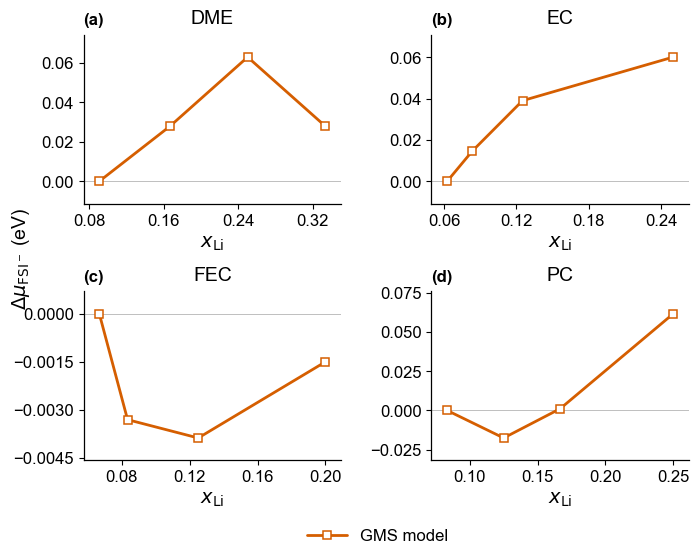

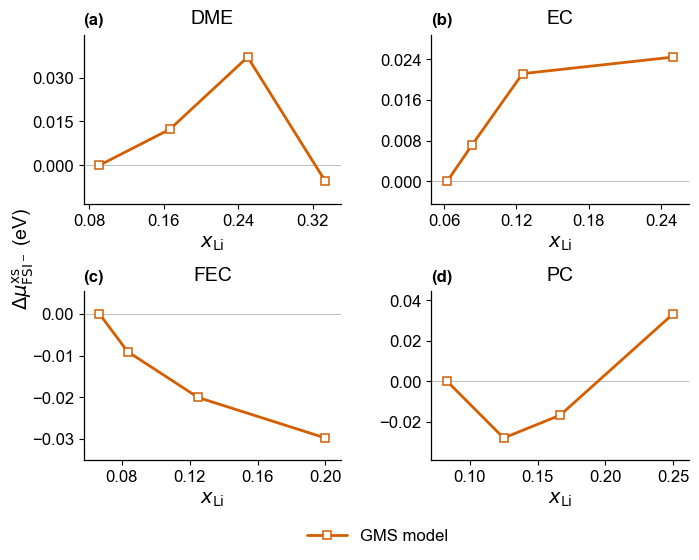

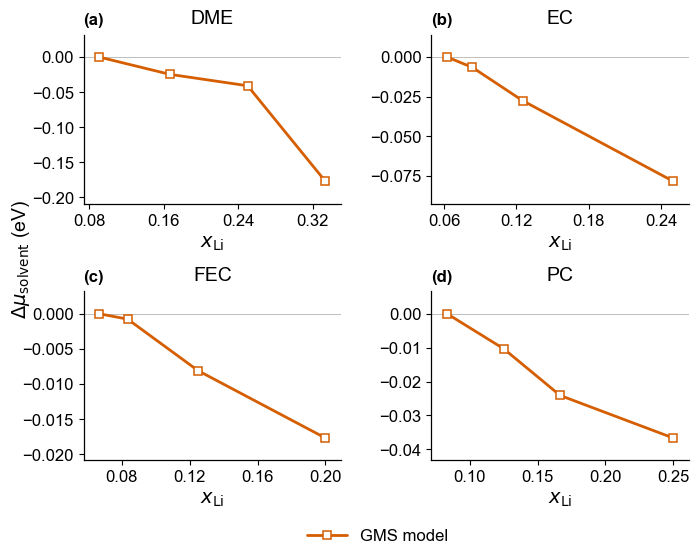

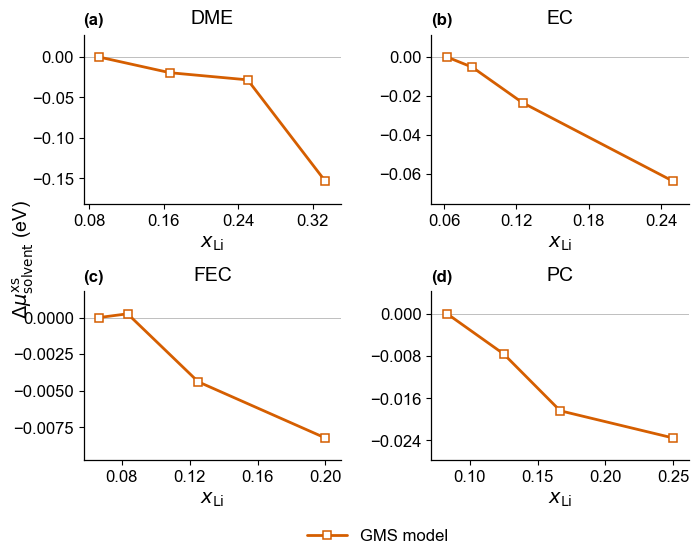

In [19]:
def plot_species_chemical_potentials(
    frame: pd.DataFrame,
    species: str,
    quantity: str = "Mix",
) -> tuple[plt.Figure, np.ndarray]:
    """Four-panel model-only full/excess shifts for one species."""
    if species not in SPECIES_COLUMNS or quantity not in ("Mix", "E"):
        raise ValueError("Use a recognized species and quantity 'Mix' or 'E'")
    solvents = ("DME", "EC", "FEC", "PC")
    value_column = f"delta_mu{quantity}_{species}_vs_dilute"
    label = SPECIES_PLOT_LABELS[species]
    superscript = r"^{\mathrm{xs}}" if quantity == "E" else ""
    with plt.rc_context(PUBLICATION_STYLE):
        fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.6), sharey=False)
        fig.subplots_adjust(left=0.12, right=0.985, bottom=0.19, top=0.95,
                            wspace=0.35, hspace=0.52)
        for letter, ax, solvent in zip("abcd", axes.flat, solvents):
            subset = frame.loc[frame["Solvent"] == solvent].sort_values("x_Li")
            if subset.empty:
                raise ValueError(f"Missing model results for {solvent}")
            ax.axhline(0, color="0.75", linewidth=0.7, zorder=0)
            ax.plot(subset["x_Li"], subset[value_column], color="#D55E00",
                    linestyle="-", marker="s", linewidth=2.0, markersize=5.2,
                    markerfacecolor="white", markeredgewidth=1.1,
                    label="GMS model", zorder=3)
            ax.set_title(solvent, pad=8)
            ax.text(0.0, 1.04, f"({letter})", transform=ax.transAxes,
                    ha="left", va="bottom", fontsize=12, fontweight="bold")
            ax.set_xlabel(r"$x_{\mathrm{Li}}$", labelpad=4)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.tick_params(axis="both", direction="out", length=3.5, width=0.8,
                           top=False, right=False)
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            ax.margins(x=0.07, y=0.18)
        fig.supylabel(rf"$\Delta\mu_{{{label}}}{superscript}$ ({ENERGY_UNIT})",
                      x=0.015, y=0.55, fontsize=14)
        handles, labels = axes[0,0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.54,0.015),
                   ncol=1, frameon=False, handlelength=2.4, columnspacing=1.8)
    return fig, axes

species_figures = {}
for species in ("FSI", "Solvent"):
    for quantity in ("Mix", "E"):
        species_figures[(species, quantity)] = plot_species_chemical_potentials(
            relative_results, species, quantity
        )
        plt.show()


## 10. Optional exports

Set the export flags in Section 1 to write tables and figures to `OUTPUT_DIR`.

In [ ]:
if EXPORT_FIGURES or EXPORT_TABLES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if EXPORT_FIGURES:
    figure_sets = {"GMS_Li_experiment_4panel": gms_experiment_figure,
                   **{f"GMS_{species}_{quantity}_4panel": value
                      for (species, quantity), value in species_figures.items()}}
    for name, (figure, _) in figure_sets.items():
        # Keep the fixed canvas dimensions; do not crop with bbox_inches='tight'.
        with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42}):
            figure.savefig(OUTPUT_DIR / f"{name}.pdf", facecolor="white", bbox_inches=None)
        figure.savefig(OUTPUT_DIR / f"{name}.png", dpi=330, facecolor="white", bbox_inches=None)
    for solvent, (figure, _) in rdf_cn_figures.items():
        figure.savefig(OUTPUT_DIR / f"GMS_{solvent}_RDF_CN.pdf", bbox_inches=None)
    for (species, quantity), (figure, _) in extrapolation_figures.items():
        figure.savefig(OUTPUT_DIR / f"GMS_{species}_{quantity}_extrapolation.pdf", bbox_inches=None)

if EXPORT_TABLES:
    tables = {"pointwise": results, "rdf_cn_parameters": parameter_diagnostics,
              "relative_chemical_potentials": relative_results,
              "extrapolation": extrapolation_results,
              "experiment_references": comparison_references,
              "experiment_matches": comparison_matches,
              "experiment_metrics": comparison_metrics}
    for name, table in tables.items():
        table.to_csv(OUTPUT_DIR / f"GMS_{name}.csv", index=False)
